<a href="https://colab.research.google.com/github/Yashji12-matrix/FIRST/blob/main/TSFM_Conformal_Study_Dissertation.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Can you trust the prediction intervals of time-series foundation models after their training cutoff?

**A rolling-origin, leakage-aware study with conformal recalibration, on open exchange-rate, US-market and farm-weather data.**

## Why this question (the knowledge gaps)

Pretrained forecasters (Chronos, TimesFM, ...) are strong on benchmarks, but three points in the recent literature are open:

| Open point | Where it is stated |
|---|---|
| On data from **after** a model's training period, the intervals of pretrained models **undercover** while classical ones overcover. Whether **conformal recalibration repairs this** is not tested. | Pretraining-familiarity study, arXiv:2609.10357 |
| That study uses **one forecast origin**, so it cannot say how much results vary over time. | same paper, stated limitation |
| Conformal methods for time series have been benchmarked with **AutoARIMA on one sales dataset**, not with foundation models. | arXiv:2601.18509 |
| The **size of temporal leakage** in real foundation-model evaluations is "largely unknown". | arXiv:2510.13654 |

## Research questions

1. **RQ1.** After the release date of each model (so the data are guaranteed unseen), do its native 80% intervals hold? Is coverage lower than before release, relative to a classical control that cannot have seen the data?
2. **RQ2.** Do rolling split-conformal, CQR and adaptive conformal (ACI) restore 80% coverage, and what do they cost in interval width?
3. **RQ3.** Does the point-forecast advantage over classical models shrink after release?

## Design in one paragraph

About 110 daily series (ECB exchange rates, FRED market series, ERA5 weather at 24 farm regions) are forecast 14 steps ahead from **weekly origins** over three years. Seven forecasters are compared:
three classical (seasonal naive, Theta, climatology + AR(1)) and four pretrained (Chronos-Bolt small and base, Chronos-2, TimesFM 2.5). For each pretrained model the year **before** and the year **after** its release date are compared. Conformal methods use only outcomes that
would really have been observed at each origin (this is tested). Every statistic is a bootstrap over series. The conclusion at the end is written by code from the numbers, so a null result is reported as null.

**What is real:** all data are real and open (no API key). **What is a limit:** release dates stand in for training cutoffs (documented cutoffs are not available), and these are the only domains tested.

## 1. Setup

**This notebook is self-contained.** The next cells write the project's code files (`tsfm_calib/*.py`) into the current folder, so you do not need to upload anything else.
Run them in order. On Colab, run the install cell first (it takes a minute; if it asks you to restart the session, do so and then run all cells again from the top).

In [1]:
# Install the libraries once (Colab already has numpy, pandas, scipy, matplotlib, torch).
!pip -q install chronos-forecasting transformers accelerate "pandas[pyarrow]" joblib requests

In [2]:
import os
os.makedirs("tsfm_calib", exist_ok=True)

In [3]:
%%writefile tsfm_calib/__init__.py
"""tsfm_calib: do time-series foundation models give trustworthy prediction intervals after their training cutoff?

Modules (in the order the study uses them):
    config       every setting, the model list with release dates, the weather locations
    data         downloads (ECB, FRED, Open-Meteo), cleaning, caching
    forecasters  classical baselines and wrappers for Chronos-Bolt, Chronos-2 and TimesFM 2.5
    pipeline     runs every forecaster over many rolling forecast origins and caches the result
    conformal    native / split-conformal / CQR / adaptive (ACI) intervals with NO look-ahead
    evaluate     windows around each model's release date, metrics, paired cluster bootstrap
    figures      all plots
    report       the written conclusion, computed from the numbers
"""
__version__ = "1.0"

Writing tsfm_calib/__init__.py


In [4]:
%%writefile tsfm_calib/config.py
"""All settings live here. Change values in this file (or override them when you build `Cfg`), not inside functions."""
from dataclasses import dataclass, field
from datetime import date

# The quantile levels every forecaster must return. 0.1 and 0.9 give the 80% interval used everywhere in the study.
QLEVELS = (0.1, 0.5, 0.9)
NOMINAL = 0.8          # nominal coverage of the central interval (alpha = 0.2)

# ---------------------------------------------------------------------------------------------------------------
# Pretrained models. `released` is the public release date of the checkpoint. It is an UPPER BOUND for the end of
# the training data (a model cannot have seen data from after it was published), so "targets after `released`" are
# guaranteed new to the model. Training cutoffs themselves are not reliably documented; see README.
# Dates come from the projects' own release notes (checked when this code was written):
#   Chronos-Bolt 26 Nov 2024 and Chronos-2 20 Oct 2025: README of github.com/amazon-science/chronos-forecasting
#   TimesFM 2.5 15 Sep 2025: README of github.com/google-research/timesfm
# ---------------------------------------------------------------------------------------------------------------
FOUNDATION_MODELS = {
    "chronos_bolt_small": dict(kind="chronos_bolt", repo="amazon/chronos-bolt-small", released="2024-11-26", label="Chronos-Bolt small"),
    "chronos_bolt_base":  dict(kind="chronos_bolt", repo="amazon/chronos-bolt-base",  released="2024-11-26", label="Chronos-Bolt base"),
    "chronos_2":          dict(kind="chronos_2",    repo="amazon/chronos-2",          released="2025-10-20", label="Chronos-2"),
    "timesfm_2_5":        dict(kind="timesfm_2_5",  repo="google/timesfm-2.5-200m-transformers", max_batch=16, released="2025-09-15", label="TimesFM 2.5"),
}

CLASSICAL_MODELS = {
    "snaive": "Seasonal naive",
    "theta":  "Theta",
    "clim_ar1": "Climatology + AR(1) (weather only)",
}

# Agricultural regions for the weather domain (latitude, longitude). Chosen to span major maize/wheat/rice areas on
# four continents, in line with an agriculture and climate interest. Names are only labels.
WEATHER_SITES = {
    "Iowa_US": (42.0, -93.5), "Illinois_US": (40.0, -89.0), "Kansas_US": (38.5, -98.5),
    "Punjab_IN": (30.9, 75.8), "UttarPradesh_IN": (27.0, 80.5), "Henan_CN": (34.0, 113.5),
    "Heilongjiang_CN": (47.0, 127.0), "MatoGrosso_BR": (-13.0, -56.0), "Parana_BR": (-24.5, -51.5),
    "BuenosAires_AR": (-35.5, -60.0), "Cordoba_AR": (-32.0, -63.5), "RiftValley_KE": (-0.3, 36.0),
    "Central_ZM": (-14.5, 28.0), "Central_MW": (-13.5, 33.8), "Oromia_ET": (8.5, 39.0),
    "FreeState_ZA": (-28.5, 27.0), "Kaduna_NG": (10.5, 7.4), "Ashanti_GH": (6.7, -1.6),
    "Mbeya_TZ": (-8.9, 33.4), "Beauce_FR": (48.4, 1.8), "Poltava_UA": (49.6, 34.5),
    "Wheatbelt_AU": (-31.5, 117.5), "NileDelta_EG": (30.8, 31.0), "Pampa_UY": (-33.0, -56.0),
}
WEATHER_VARS = {"temperature_2m_mean": "temp_mean", "shortwave_radiation_sum": "radiation", "precipitation_sum": "precip"}

# Daily series from FRED (no key needed for the CSV download). Business-day data.
FRED_SERIES = ["DGS3MO", "DGS2", "DGS5", "DGS10", "DGS30", "T10Y2Y", "DCOILWTICO", "DCOILBRENTEU", "DHHNGSP",
               "SP500", "NASDAQCOM", "VIXCLS", "BAMLH0A0HYM2", "DTWEXBGS"]


@dataclass
class Cfg:
    # --- folders ---------------------------------------------------------------------------------------------
    cache_dir: str = "cache"            # downloads and model forecasts are stored here, so reruns are instant
    out_dir: str = "outputs"            # figures, tables, conclusion
    # --- data ------------------------------------------------------------------------------------------------
    data_start: str = "2021-01-01"      # first observation downloaded (we need 512 steps of context before the first origin)
    data_end: str = ""                  # "" = today minus `end_lag_days`
    end_lag_days: int = 7               # ERA5 in Open-Meteo is about 5 days behind real time
    min_series_obs: int = 900           # a series needs this many observations
    max_missing_share: float = 0.05     # drop a series with more missing values than this (after the first valid day)
    max_fx_series: int = 40
    fred_api_key: str = ""              # optional free key from https://fredaccount.stlouisfed.org/apikeys (more reliable than the public CSV)
    # --- forecasting set-up ---------------------------------------------------------------------------------
    context_len: int = 512              # observations given to every model
    horizon: int = 14                   # steps ahead (days for weather, trading days for FX and FRED)
    eval_horizons: tuple = (1, 3, 7, 14)  # horizons reported (all 14 are forecast)
    first_origin: str = "2023-06-01"    # first forecast origin; the weeks before the first window feed the calibration
    origin_stride_days: int = 7         # one forecast origin per week
    # --- conformal -------------------------------------------------------------------------------------------
    alpha: float = 1 - NOMINAL
    cal_window: int = 26                # use the last 26 usable origins (about half a year) as calibration scores
    min_cal: int = 10                   # fewer usable origins than this: no conformal interval
    aci_gamma: float = 0.02             # step size of adaptive conformal inference
    # --- windows around each release date ---------------------------------------------------------------------
    window_days: int = 365              # pre-release window: the year before release; post: the year after
    # --- statistics --------------------------------------------------------------------------------------------
    n_boot: int = 2000
    seed: int = 7
    # --- compute ------------------------------------------------------------------------------------------------
    batch_size: int = 128               # series per batch for neural models
    device: str = "auto"                # "auto", "cuda", "cpu" or "mps"
    n_jobs: int = 2                     # parallel workers for the classical models
    models: tuple = ("chronos_bolt_small", "chronos_bolt_base", "chronos_2", "timesfm_2_5")
    classical: tuple = ("snaive", "theta", "clim_ar1")
    quick: bool = False                 # True: few series and origins, for a first run

    def end_date(self):
        if self.data_end:
            return self.data_end
        return str(date.fromordinal(date.today().toordinal() - self.end_lag_days))

Writing tsfm_calib/config.py


In [5]:
%%writefile tsfm_calib/data.py
"""Data: three open sources, no API key needed.

    fx      ECB euro reference rates, daily (business days)          https://data.ecb.europa.eu
    fred    US rates, oil, gas, equity, volatility, credit, dollar    https://fred.stlouisfed.org
    weather ERA5 reanalysis via Open-Meteo, daily, 24 farm regions    https://open-meteo.com

Every download is cached as a CSV in `cache_dir`, so a rerun does not hit the web again.
Each cleaned series becomes a `Series`: dates (numpy datetime64[D]) and float values, plus its domain."""
from __future__ import annotations
import io, json, os, time
from dataclasses import dataclass
import numpy as np
import pandas as pd

from .config import Cfg, FRED_SERIES, WEATHER_SITES, WEATHER_VARS

HEADERS = {"User-Agent": "tsfm-calib/1.0 (academic dissertation project)"}


@dataclass
class Series:
    name: str
    domain: str                 # "fx", "fred" or "weather"
    dates: np.ndarray           # datetime64[D], strictly increasing
    values: np.ndarray          # float64, no NaN

    def __len__(self):
        return len(self.values)


def http_get_text(url: str, params: dict | None = None, retries: int = 5, pause: float = 2.0, timeout: int = 120) -> str:
    """GET a URL and return the text.

    Retries with growing waits. A per-minute rate limit (HTTP 429 mentioning "minute", as Open-Meteo sends)
    is waited out for 65 s and does not use up a normal retry (at most 8 such waits per call).
    """
    import requests
    last, tries, rate_waits = None, 0, 0
    while tries < retries:
        wait = pause * (tries + 1)
        counts_as_try = True
        try:
            r = requests.get(url, params=params, headers=HEADERS, timeout=timeout)
            if r.status_code == 200:
                return r.text
            last = f"HTTP {r.status_code}: {r.text[:200]}"
            if r.status_code == 429:
                if "minute" in r.text.lower() and rate_waits < 8:
                    wait, counts_as_try, rate_waits = 65, False, rate_waits + 1
                elif "hourly" in r.text.lower() or "daily" in r.text.lower():
                    raise RuntimeError(f"Rate limit will not clear soon: {r.text[:200]}. Try again later.")
        except RuntimeError:
            raise
        except Exception as e:                      # network hiccup
            last = repr(e)
        time.sleep(wait)
        tries += 1 if counts_as_try else 0
    raise RuntimeError(f"Download failed after {retries} tries: {url}\n  last error: {last}")


def _cached(cfg: Cfg, fname: str, fetch):
    """Return the cached CSV text if it exists, otherwise fetch, store and return it."""
    os.makedirs(cfg.cache_dir, exist_ok=True)
    path = os.path.join(cfg.cache_dir, fname)
    if os.path.exists(path):
        return open(path, encoding="utf-8").read()
    text = fetch()
    open(path, "w", encoding="utf-8").write(text)
    return text


# ------------------------------------------------------------------------------------------------ ECB FX
def load_fx(cfg: Cfg) -> list[Series]:
    """All daily euro reference rates (currency per 1 EUR). Series key: D..EUR.SP00.A  ('..' = every currency)."""
    url = "https://data-api.ecb.europa.eu/service/data/EXR/D..EUR.SP00.A"
    params = {"format": "csvdata", "startPeriod": cfg.data_start}
    text = _cached(cfg, f"ecb_fx_{cfg.data_start}.csv", lambda: http_get_text(url, params))
    df = pd.read_csv(io.StringIO(text))
    need = {"CURRENCY", "TIME_PERIOD", "OBS_VALUE"}
    if not need <= set(df.columns):
        raise RuntimeError(f"Unexpected ECB CSV columns {list(df.columns)}; expected {sorted(need)}. "
                           "Delete the cached file and check https://data.ecb.europa.eu/help/api/data")
    out = []
    for cur, g in df.groupby("CURRENCY"):
        g = g.sort_values("TIME_PERIOD")
        out.append(_make_series(f"EURx{cur}", "fx", g["TIME_PERIOD"], g["OBS_VALUE"], cfg, business_day=True))
    return [s for s in out if s is not None][: cfg.max_fx_series]


# ------------------------------------------------------------------------------------------------ FRED
def _fred_csv_public(cfg: Cfg, sid: str):
    """Public CSV endpoint (no key). It is sometimes slow or blocked from cloud notebooks, so we give it a short timeout."""
    url = "https://fred.stlouisfed.org/graph/fredgraph.csv"
    text = _cached(cfg, f"fred_{sid}_{cfg.data_start}.csv",
                   lambda: http_get_text(url, {"id": sid, "cosd": cfg.data_start}, retries=2, pause=1.0, timeout=40))
    df = pd.read_csv(io.StringIO(text))
    val = pd.to_numeric(df[sid] if sid in df.columns else df.iloc[:, 1], errors="coerce")   # "." marks missing
    return df[df.columns[0]], val                      # first column is "observation_date" (new) or "DATE" (old)


def _fred_api(cfg: Cfg, sid: str, key: str):
    """Official FRED API (free key: https://fredaccount.stlouisfed.org/apikeys). Much more reliable from Colab."""
    url = "https://api.stlouisfed.org/fred/series/observations"
    params = {"series_id": sid, "api_key": key, "file_type": "json", "observation_start": cfg.data_start}
    text = _cached(cfg, f"fredapi_{sid}_{cfg.data_start}.json", lambda: http_get_text(url, params, retries=3, pause=2.0, timeout=60))
    obs = json.loads(text)["observations"]
    return pd.Series([o["date"] for o in obs]), pd.to_numeric(pd.Series([o["value"] for o in obs]), errors="coerce")


def load_fred(cfg: Cfg, say=print) -> list[Series]:
    """Daily FRED series. Uses the official API if a key is set (cfg.fred_api_key or the FRED_API_KEY environment variable),
    otherwise the public CSV endpoint. A series that cannot be downloaded is skipped with a message, not fatal."""
    key = cfg.fred_api_key or os.environ.get("FRED_API_KEY", "")
    out, failed = [], []
    for sid in FRED_SERIES:
        try:
            d, v = _fred_api(cfg, sid, key) if key else _fred_csv_public(cfg, sid)
        except Exception as e:
            failed.append(sid)
            if len(failed) == 3 and not out:           # three failures in a row and nothing worked: stop wasting time
                say("  FRED: the first three downloads failed, skipping the FRED domain (see the note below)")
                break
            continue
        s = _make_series(f"FRED_{sid}", "fred", d, v, cfg, business_day=True)
        if s is not None:
            out.append(s)
    if failed:
        say(f"  FRED: {len(failed)} of {len(FRED_SERIES)} series could not be downloaded ({', '.join(failed[:5])}{' ...' if len(failed) > 5 else ''}). "
            "Fix: get a free API key at https://fredaccount.stlouisfed.org/apikeys and set cfg.fred_api_key (or FRED_API_KEY), then re-run. "
            "The study also runs without this domain.")
    return out


# ------------------------------------------------------------------------------------------------ Open-Meteo
def load_weather(cfg: Cfg) -> list[Series]:
    """Daily ERA5 weather per site. We request only documented variables: max and min 2 m temperature (we use their
    midpoint, a standard daily mean proxy), shortwave radiation sum and precipitation sum."""
    url = "https://archive-api.open-meteo.com/v1/archive"
    end = cfg.end_date()
    out = []
    for site, (lat, lon) in WEATHER_SITES.items():
        params = {"latitude": lat, "longitude": lon, "start_date": cfg.data_start, "end_date": end,
                  "daily": "temperature_2m_max,temperature_2m_min,shortwave_radiation_sum,precipitation_sum",
                  "timezone": "UTC"}
        text = _cached(cfg, f"openmeteo_{site}_{cfg.data_start}_{end}.json", lambda p=params: http_get_text(url, p))
        js = json.loads(text)
        if "daily" not in js:
            raise RuntimeError(f"Open-Meteo returned no daily data for {site}: {str(js)[:200]}")
        d = js["daily"]
        t = pd.to_datetime(d["time"])
        cols = {"temp_mid": (np.array(d["temperature_2m_max"], float) + np.array(d["temperature_2m_min"], float)) / 2,
                "radiation": np.array(d["shortwave_radiation_sum"], float),
                "precip": np.array(d["precipitation_sum"], float)}
        for vname, vals in cols.items():
            s = _make_series(f"{site}:{vname}", "weather", t, vals, cfg, business_day=False)
            if s is not None:
                out.append(s)
        time.sleep(3.0)                                # be polite: the free API limits requests per minute and Colab IPs are shared
    return out


# ------------------------------------------------------------------------------------------------ cleaning
def _make_series(name, domain, dates, values, cfg: Cfg, business_day: bool) -> Series | None:
    """Turn raw columns into a clean Series, or None if the series is unusable (reason is silent but counted by the caller)."""
    d = pd.to_datetime(pd.Series(dates).reset_index(drop=True))
    v = pd.to_numeric(pd.Series(values).reset_index(drop=True), errors="coerce")
    df = pd.DataFrame({"d": d, "v": v}).dropna(subset=["d"]).drop_duplicates("d").sort_values("d")
    df = df[df["d"] <= pd.Timestamp(cfg.end_date())]
    if df.empty:
        return None
    if business_day:
        df = df.dropna(subset=["v"])                   # holidays are simply not observed
    else:                                              # calendar-daily data: fill short gaps, reject long ones
        full = pd.date_range(df["d"].iloc[0], df["d"].iloc[-1], freq="D")
        df = df.set_index("d").reindex(full).rename_axis("d").reset_index()
        miss = df["v"].isna().mean()
        if miss > cfg.max_missing_share:
            return None
        df["v"] = df["v"].interpolate(limit=3, limit_direction="both")
        df = df.dropna(subset=["v"])
    if len(df) < cfg.min_series_obs:
        return None
    vals = df["v"].to_numpy(float)
    if np.nanstd(vals) == 0:
        return None
    if domain == "weather" and name.endswith("precip") and (vals == 0).mean() > 0.9:
        return None                                    # an almost-always-dry site has no scale to measure error against
    # the series must reach (close to) the end of the study period, otherwise it has no post-release data
    if (pd.Timestamp(cfg.end_date()) - df["d"].iloc[-1]).days > 15:
        return None
    return Series(name, domain, df["d"].to_numpy("datetime64[D]"), vals)


def load_all(cfg: Cfg, say=print) -> list[Series]:
    """Download (or read from cache) every source and report what was kept."""
    allseries = []
    for label, fn in (("ECB exchange rates", load_fx), ("FRED daily series", lambda c: load_fred(c, say)), ("ERA5 weather (Open-Meteo)", load_weather)):
        try:
            got = fn(cfg)
        except Exception as e:                         # one failed source must not stop the whole study
            say(f"  !! {label} could not be loaded and is skipped: {type(e).__name__}: {str(e)[:200]}")
            got = []
        say(f"  {label}: {len(got)} usable series")
        allseries += got
    missing = [d for d in ("fx", "fred", "weather") if not any(s.domain == d for s in allseries)]
    if missing:
        say("\n  !!! THE STUDY IS INCOMPLETE: no data for " + ", ".join(missing) + ". Fix the download (messages above) and re-run this cell "
            "before using any result. Do not report a run with a missing domain as the full study.\n")
    if cfg.quick:                                      # quick mode keeps a handful per domain
        keep = []
        for dom in ("fx", "fred", "weather"):
            keep += [s for s in allseries if s.domain == dom][:6]
        allseries = keep
    return allseries

Writing tsfm_calib/data.py


In [6]:
%%writefile tsfm_calib/forecasters.py
"""Forecasters. Every forecaster has the same interface:

    fc.forecast(hist, end_dates, H) -> array (n_series, H, 3)

        hist       list of 1-D float arrays: the FULL history of each series up to the forecast origin
        end_dates  numpy datetime64[D] array: the date of the last observation of each history
        H          number of steps ahead
        returns    the 0.1, 0.5 and 0.9 quantile forecasts (QLEVELS), already sorted so they cannot cross

Classical models (seasonal naive, Theta, climatology + AR(1)) are written in numpy so the study has no hidden
dependency, and their intervals are Gaussian with a variance taken from their own in-sample errors.
Foundation models are thin wrappers; each one asserts the shape and ordering of what the library returns."""
from __future__ import annotations
import numpy as np
import pandas as pd
from scipy.stats import norm

from .config import Cfg, QLEVELS, FOUNDATION_MODELS

Z = norm.ppf(np.array(QLEVELS))           # z-scores of the three quantile levels


def _gauss_quantiles(med: np.ndarray, sd: np.ndarray) -> np.ndarray:
    """med, sd: (n, H) -> (n, H, 3) Gaussian quantiles."""
    return med[..., None] + sd[..., None] * Z[None, None, :]


class Forecaster:
    name = "base"
    is_foundation = False

    def applies(self, domain: str) -> bool:
        return True

    def forecast(self, hist, end_dates, H: int) -> np.ndarray:
        raise NotImplementedError


# =============================================================================================== classical models
class SeasonalNaive(Forecaster):
    """Repeat the value one season ago. Season = 365 days for weather (annual cycle), 1 step (random walk) for markets."""
    name = "snaive"

    def __init__(self, domains_season=None):
        self.season = domains_season or {"weather": 365, "fx": 1, "fred": 1}

    def forecast(self, hist, end_dates, H, domains=None):
        n = len(hist)
        out = np.empty((n, H, 3))
        for i, y in enumerate(hist):
            m = self.season.get(domains[i] if domains is not None else "fx", 1)
            m = m if len(y) > 2 * m else 1
            d = y[m:] - y[:-m]                                   # seasonal differences = the model's own errors
            sig = float(np.std(d)) if len(d) > 2 else float(np.std(y)) + 1e-9
            h = np.arange(1, H + 1)
            k = np.ceil(h / m)                                   # how many seasons ahead
            # value one season before the target date: index (last index + h) - m*k  =  len(y) - 1 + h - m*k
            med = np.array([y[len(y) - 1 + int(hh) - m * int(kk)] if m > 1 else y[-1] for hh, kk in zip(h, k)])
            out[i] = _gauss_quantiles(med[None, :], (sig * np.sqrt(k))[None, :])[0]
        return out


class Theta(Forecaster):
    """Standard Theta method (Assimakopoulos & Nikolopoulos 2000) in the Hyndman-Billah form:
    simple exponential smoothing forecast plus half the linear-trend slope. The smoothing weight is chosen by a grid
    search on in-sample squared error, all weights at once (vectorised), so it is fast."""
    name = "theta"
    ALPHAS = np.geomspace(0.02, 0.99, 18)

    def forecast(self, hist, end_dates, H, domains=None):
        n = len(hist)
        out = np.empty((n, H, 3))
        a = self.ALPHAS
        for i, y in enumerate(hist):
            y = np.asarray(y[-512:], float)
            L = len(y)
            lvl = np.full(a.shape, y[0])
            sse = np.zeros(a.shape)
            for t in range(1, L):                                # SES recursion for all alphas at once
                e = y[t] - lvl
                sse += e * e
                lvl = lvl + a * e
            j = int(np.argmin(sse))
            alpha, level = a[j], lvl[j]
            sigma = float(np.sqrt(sse[j] / (L - 1)))
            b = np.polyfit(np.arange(L), y, 1)[0]                # OLS slope of the linear trend
            h = np.arange(1, H + 1)
            med = level + 0.5 * b * (h - 1 + 1 / alpha - (1 - alpha) ** L / alpha)
            sd = sigma * np.sqrt(1 + (h - 1) * alpha ** 2)       # SES forecast-error standard deviation
            out[i] = _gauss_quantiles(med[None], sd[None])[0]
        return out


class ClimatologyAR1(Forecaster):
    """Weather-only baseline: day-of-year climatology (mean of the same calendar window in earlier years, +-7 days)
    plus an AR(1) on the anomaly. This is the standard 'persistence of anomalies' reference in agro-meteorology and
    a strong control for seasonal weather series."""
    name = "clim_ar1"

    def applies(self, domain):
        return domain == "weather"

    def forecast(self, hist, end_dates, H, domains=None):
        n = len(hist)
        out = np.empty((n, H, 3))
        for i, (y, end) in enumerate(zip(hist, end_dates)):
            y = np.asarray(y, float)
            dates = pd.to_datetime(end) - pd.to_timedelta(np.arange(len(y) - 1, -1, -1), unit="D")
            doy = (dates.dayofyear.to_numpy() - 1) % 365
            clim = np.zeros(365)
            for d in range(365):
                dist = np.minimum(np.abs(doy - d), 365 - np.abs(doy - d))
                clim[d] = y[dist <= 7].mean()
            anom = y - clim[doy]
            phi = float(np.clip(np.dot(anom[1:], anom[:-1]) / np.dot(anom[:-1], anom[:-1]), 0.0, 0.99))
            sig_e = float(np.std(anom[1:] - phi * anom[:-1])) + 1e-9
            h = np.arange(1, H + 1)
            fdoy = (((pd.to_datetime(end) + pd.to_timedelta(h, unit="D")).dayofyear.to_numpy()) - 1) % 365
            med = clim[fdoy] + phi ** h * anom[-1]
            sd = sig_e * np.sqrt((1 - phi ** (2 * h)) / (1 - phi ** 2 + 1e-12))
            out[i] = _gauss_quantiles(med[None], sd[None])[0]
        return out


# =============================================================================================== foundation models
def _pick_device(pref: str) -> str:
    if pref != "auto":
        return pref
    try:
        import torch
    except ImportError:
        return "cpu"
    if torch.cuda.is_available():
        return "cuda"
    if getattr(torch.backends, "mps", None) and torch.backends.mps.is_available():
        return "mps"
    return "cpu"


class FoundationModel(Forecaster):
    """Common batching, context slicing and sanity checks for pretrained models."""
    is_foundation = True

    def __init__(self, key: str, cfg: Cfg):
        self.key, self.cfg = key, cfg
        self.spec = FOUNDATION_MODELS[key]
        self.name = key
        self.device = _pick_device(cfg.device)
        self._model = None

    def _contexts(self, hist):
        """Last `context_len` observations, left-padded with the first value if a history is shorter."""
        L = self.cfg.context_len
        arr = np.empty((len(hist), L), dtype=np.float32)
        for i, y in enumerate(hist):
            y = np.asarray(y, dtype=np.float32)[-L:]
            arr[i, L - len(y):] = y
            arr[i, : L - len(y)] = y[0]
        return arr

    def forecast(self, hist, end_dates, H, domains=None):
        ctx = self._contexts(hist)
        parts = []
        bs = min(self.cfg.batch_size, self.spec.get("max_batch", self.cfg.batch_size))
        s = 0
        while s < len(ctx):
            try:
                q = self._predict_batch(ctx[s:s + bs], H)                    # (b, H, 3)
            except Exception as e:
                if "out of memory" in str(e).lower() and bs > 1:             # GPU too small: halve the batch and retry
                    bs = max(1, bs // 2)
                    self._free_gpu()
                    print(f"    [{self.name}] GPU out of memory -> batch size {bs}")
                    continue
                raise
            parts.append(q)
            s += bs
        self._free_gpu()
        out = np.concatenate(parts, 0).astype(np.float64)
        return np.sort(out, axis=-1)                                          # forbid quantile crossing

    def _free_gpu(self):
        try:
            import gc, torch
            gc.collect()
            if torch.cuda.is_available():
                torch.cuda.empty_cache()
        except Exception:
            pass

    def release(self):
        """Drop the model from memory (called between models so the next one has the whole GPU)."""
        self._model = None
        self._free_gpu()

    def _predict_batch(self, ctx, H):
        raise NotImplementedError


class ChronosBolt(FoundationModel):
    """Chronos-Bolt. `pipeline.predict(context, prediction_length)` returns [n_series, n_quantiles, H] (model card).
    The model's nine quantile levels are 0.1 ... 0.9; we take the 1st, 5th and 9th."""

    def _load(self):
        import torch
        from chronos import BaseChronosPipeline
        kw = dict(device_map=self.device)
        try:
            self._model = BaseChronosPipeline.from_pretrained(self.spec["repo"], torch_dtype=torch.bfloat16 if self.device == "cuda" else torch.float32, **kw)
        except TypeError:
            self._model = BaseChronosPipeline.from_pretrained(self.spec["repo"], **kw)

    def _predict_batch(self, ctx, H):
        import torch
        if self._model is None:
            self._load()
        with torch.no_grad():
            series = [torch.tensor(c) for c in ctx]
            try:                                                             # chronos >= 2: first argument is `inputs`
                q = self._model.predict(series, prediction_length=H)
            except TypeError:                                                # older releases name it `context`
                q = self._model.predict(context=series, prediction_length=H)
        if isinstance(q, (list, tuple)):                                     # some versions return one tensor per series
            q = torch.stack([torch.as_tensor(x) for x in q])
        q = q.float().cpu().numpy()                                          # [b, nq, H]
        assert q.ndim == 3 and q.shape[1] == 9 and q.shape[2] >= H, f"unexpected Chronos-Bolt output shape {q.shape}"
        return np.transpose(q[:, [0, 4, 8], :H], (0, 2, 1))                   # -> (b, H, 3)


class Chronos2(FoundationModel):
    """Chronos-2 through `predict_df` (documented in the project README): long data frame with id, timestamp, target."""

    def _load(self):
        from chronos import Chronos2Pipeline
        self._model = Chronos2Pipeline.from_pretrained(self.spec["repo"], device_map=self.device)

    def _predict_batch(self, ctx, H):
        if self._model is None:
            self._load()
        b, L = ctx.shape
        # The model only uses the order of the values, so we give every series the same synthetic daily time stamps.
        ts = pd.date_range("2000-01-01", periods=L, freq="D")
        ids = [f"s{j:05d}" for j in range(b)]
        df = pd.DataFrame({"id": np.repeat(ids, L), "timestamp": np.tile(ts, b), "target": ctx.reshape(-1)})
        pred = self._model.predict_df(df, prediction_length=H, quantile_levels=list(QLEVELS),
                                      id_column="id", timestamp_column="timestamp", target="target")
        pred = pred.reset_index() if "id" not in pred.columns else pred
        pred = pred.sort_values(["id", "timestamp"])
        assert len(pred) == b * H, f"Chronos-2 returned {len(pred)} rows, expected {b * H}"
        cols = [str(q) for q in QLEVELS]
        miss = [c for c in cols if c not in pred.columns]
        assert not miss, f"Chronos-2 output lacks quantile columns {miss}; columns are {list(pred.columns)}"
        return pred[cols].to_numpy(float).reshape(b, H, 3)


class TimesFM25(FoundationModel):
    """TimesFM 2.5 through the Hugging Face `transformers` port. `full_predictions` is (batch, 128, k): the library
    documents the nine deciles 0.1 ... 0.9 and says the median is included; some versions put a mean channel first.
    We accept k = 9 or k = 10 and check that the three chosen columns are ordered, otherwise we stop."""

    def _load(self):
        from transformers import TimesFm2_5ModelForPrediction
        self._model = TimesFm2_5ModelForPrediction.from_pretrained(self.spec["repo"], device_map=self.device)

    def _predict_batch(self, ctx, H):
        import torch
        if self._model is None:
            self._load()
        dev = self._model.device
        past = [torch.tensor(c, dtype=torch.float32, device=dev) for c in ctx]
        with torch.no_grad():
            out = self._model(past_values=past, return_dict=True)
        fp = out.full_predictions.float().cpu().numpy()                      # (b, horizon_length, k)
        k = fp.shape[-1]
        assert fp.shape[1] >= H and k in (9, 10), f"unexpected TimesFM output shape {fp.shape}"
        off = 1 if k == 10 else 0
        q = fp[:, :H, [off + 0, off + 4, off + 8]]
        frac_ok = float(np.mean((q[..., 0] <= q[..., 1] + 1e-6) & (q[..., 1] <= q[..., 2] + 1e-6)))
        colmean = fp[:, :H, :].mean((0, 1))                                  # one number per output channel, for diagnosis
        # Quantile heads of TimesFM can cross a little (the study sorts them afterwards), so a few percent of crossings is fine.
        # A wrong channel mapping, in contrast, scrambles the order almost completely and the mean width is not positive.
        width_ok = float(np.mean(q[..., 2] - q[..., 0])) > 0
        assert frac_ok > 0.70 and width_ok, (f"TimesFM quantile channels look mis-mapped (ordered {frac_ok:.0%}). Channel means: "
                                             f"{np.round(colmean, 3).tolist()}; send this line to the project author")
        self.crossing_rate = 1.0 - frac_ok                                   # reported so the thesis can state how often crossing happened
        return q


# =============================================================================================== factory and smoke test
CLASSICAL_CLASSES = {"snaive": SeasonalNaive, "theta": Theta, "clim_ar1": ClimatologyAR1}
FM_CLASSES = {"chronos_bolt": ChronosBolt, "chronos_2": Chronos2, "timesfm_2_5": TimesFM25}


def make_forecaster(name: str, cfg: Cfg) -> Forecaster:
    if name in CLASSICAL_CLASSES:
        return CLASSICAL_CLASSES[name]()
    return FM_CLASSES[FOUNDATION_MODELS[name]["kind"]](name, cfg)


def smoke_test(fc: Forecaster, H: int = 14, domains=None):
    """Run a forecaster on three toy series and check shape, finiteness and quantile order. Call this before the long run."""
    t = np.arange(900)
    hist = [np.sin(t / 20.0) * 3 + 10, np.cumsum(np.random.default_rng(0).normal(size=900)) + 50, 5 + np.cos(t / 58.0)]
    end = np.array(["2024-01-01"] * 3, dtype="datetime64[D]")
    q = fc.forecast(hist, end, H, domains=["weather"] * 3) if not fc.is_foundation else fc.forecast(hist, end, H)
    assert q.shape == (3, H, 3) and np.isfinite(q).all(), f"{fc.name}: bad output {q.shape}"
    assert (q[..., 0] <= q[..., 1] + 1e-9).all() and (q[..., 1] <= q[..., 2] + 1e-9).all(), f"{fc.name}: quantiles not ordered"
    return q

Writing tsfm_calib/forecasters.py


In [7]:
%%writefile tsfm_calib/pipeline.py
"""Run every forecaster over many rolling forecast origins and keep the results.

An 'origin' is a date. At each origin a forecaster sees all data up to that date and forecasts the next H steps.
Truth for those steps is stored with its calendar date, because later we must know exactly when each outcome becomes
known (that is what keeps the conformal methods free of look-ahead)."""
from __future__ import annotations
import hashlib, json, os, time
from dataclasses import dataclass
import numpy as np
import pandas as pd

from .config import Cfg
from .data import Series
from .forecasters import Forecaster, make_forecaster

NAT = np.datetime64("NaT")


@dataclass
class Panel:
    names: list                 # series names, length S
    domains: np.ndarray         # (S,) strings
    odates: np.ndarray          # (O,) origin dates, datetime64[D]
    pos: np.ndarray             # (S, O) index of the last observation at or before each origin (-1 = unusable)
    Y: np.ndarray               # (S, O, H) realised values
    T: np.ndarray               # (S, O, H) dates of those values, datetime64[D] (NaT where unusable)
    scale: np.ndarray           # (S, O) mean absolute one-step change over the last year of history: the unit errors are measured in
    valid: np.ndarray           # (S, O) bool

    @property
    def shape(self):
        return self.Y.shape


def build_panel(series: list[Series], cfg: Cfg) -> Panel:
    """Lay out origins, realised outcomes and error scales for every series."""
    H = cfg.horizon
    last = max(s.dates[-1] for s in series)
    odates = pd.date_range(cfg.first_origin, pd.Timestamp(last) - pd.Timedelta(days=1), freq=f"{cfg.origin_stride_days}D").to_numpy("datetime64[D]")
    S, O = len(series), len(odates)
    pos = -np.ones((S, O), int)
    Y = np.full((S, O, H), np.nan)
    T = np.full((S, O, H), NAT, dtype="datetime64[D]")
    scale = np.full((S, O), np.nan)
    valid = np.zeros((S, O), bool)
    for si, s in enumerate(series):
        p = np.searchsorted(s.dates, odates, side="right") - 1          # last observation at or before the origin
        floor = 1e-3 * np.std(s.values)
        for oi in range(O):
            k = p[oi]
            stale = k < 0 or (odates[oi] - s.dates[k]).astype(int) > 5   # no recent observation
            if stale or k < cfg.context_len - 1 or k + H > len(s) - 1:
                continue
            pos[si, oi] = k
            Y[si, oi] = s.values[k + 1:k + 1 + H]
            T[si, oi] = s.dates[k + 1:k + 1 + H]
            w = s.values[max(0, k - 365):k + 1]
            scale[si, oi] = max(float(np.mean(np.abs(np.diff(w)))), floor)
            valid[si, oi] = True
    return Panel([s.name for s in series], np.array([s.domain for s in series]), odates, pos, Y, T, scale, valid)


def _cache_key(panel: Panel, cfg: Cfg) -> str:
    meta = dict(names=panel.names, o0=str(panel.odates[0]), o1=str(panel.odates[-1]), H=cfg.horizon,
                L=cfg.context_len, n=int(panel.valid.sum()))
    return hashlib.md5(json.dumps(meta, sort_keys=True).encode()).hexdigest()[:10]


def _classical_chunk(fc, hist, ends, domains, H):
    return fc.forecast(hist, ends, H, domains=domains)


def run_forecaster(fc: Forecaster, series: list[Series], panel: Panel, cfg: Cfg, say=print) -> np.ndarray:
    """Forecast quantiles (S, O, H, 3) for one forecaster; NaN where the forecaster does not apply or the origin is unusable."""
    os.makedirs(cfg.cache_dir, exist_ok=True)
    path = os.path.join(cfg.cache_dir, f"forecast_{fc.name}_{_cache_key(panel, cfg)}.npz")
    if os.path.exists(path):
        say(f"    {fc.name}: loaded from cache")
        return np.load(path)["Q"].astype(np.float64)
    S, O, H = panel.shape
    Q = np.full((S, O, H, 3), np.nan)
    items = [(si, oi) for si in range(S) for oi in range(O)
             if panel.valid[si, oi] and fc.applies(str(panel.domains[si]))]
    t0, step = time.time(), 2000 if fc.is_foundation else 400
    for a in range(0, len(items), step):
        chunk = items[a:a + step]
        hist = [series[si].values[:panel.pos[si, oi] + 1] for si, oi in chunk]
        ends = np.array([series[si].dates[panel.pos[si, oi]] for si, oi in chunk], dtype="datetime64[D]")
        doms = [str(panel.domains[si]) for si, _ in chunk]
        if fc.is_foundation:
            out = fc.forecast(hist, ends, H)
        else:                                                   # classical models are cheap: spread over processes
            from joblib import Parallel, delayed
            n = max(1, cfg.n_jobs)
            sizes = np.array_split(np.arange(len(chunk)), n)
            parts = Parallel(n_jobs=n)(delayed(_classical_chunk)(fc, [hist[i] for i in ix], ends[ix], [doms[i] for i in ix], H)
                                       for ix in sizes if len(ix))
            out = np.concatenate(parts, 0)
        for (si, oi), q in zip(chunk, out):
            Q[si, oi] = q
        say(f"    {fc.name}: {min(a + step, len(items))}/{len(items)} forecasts ({time.time() - t0:.0f}s)")
    np.savez_compressed(path, Q=Q.astype(np.float32))
    return Q


def run_all(series, panel, cfg: Cfg, forecasters: dict | None = None, say=print) -> dict:
    """Run every configured forecaster. A foundation model that cannot be loaded is reported and skipped, not fatal."""
    if forecasters is None:
        forecasters = {}
        for name in list(cfg.classical) + list(cfg.models):
            try:
                forecasters[name] = make_forecaster(name, cfg)
            except Exception as e:
                say(f"  !! cannot create {name}: {e!r}")
    out = {}
    for name, fc in forecasters.items():
        try:
            out[name] = run_forecaster(fc, series, panel, cfg, say)
        except Exception as e:
            say(f"  !! {name} failed and is skipped: {type(e).__name__}: {str(e)[:300]}")
        if hasattr(fc, "release"):                  # give the GPU back before the next model is loaded
            fc.release()
    return out

Writing tsfm_calib/pipeline.py


In [8]:
%%writefile tsfm_calib/conformal.py
"""Interval methods. Four ways to turn a model's forecast into an 80% interval for the same forecast:

    native   the model's own 0.1 and 0.9 quantiles (what you get 'for free')
    scp      rolling split conformal on the median: median +- q, q = quantile of recent absolute errors
    cqr      conformalised quantile regression (Romano et al. 2019): widen/narrow the native interval by a quantile of
             recent 'distance outside the interval' scores
    aci      CQR with adaptive conformal inference (Gibbs & Candes 2021): the target miscoverage alpha is nudged after
             every observed miss or hit, so the method reacts when the data drift

NO LOOK-AHEAD. At origin t the calibration scores for horizon h come only from earlier origins s whose target date
T[s, h] is on or before t, i.e. outcomes that have really been observed by then. This is checked in the tests."""
from __future__ import annotations
import numpy as np

from .config import Cfg


def _kth(scores: np.ndarray, alpha: float) -> float:
    """Finite-sample conformal quantile: the ceil((n+1)(1-alpha))-th smallest score (capped at the largest)."""
    n = len(scores)
    k = min(int(np.ceil((n + 1) * (1 - alpha))), n)
    return float(np.partition(scores, k - 1)[k - 1])


def conformalise(Q: np.ndarray, Y: np.ndarray, T: np.ndarray, odates: np.ndarray, valid: np.ndarray,
                 eval_h: tuple, cfg: Cfg) -> dict:
    """Return {method: (lo, hi)} with arrays of shape (S, O, len(eval_h)); NaN where an interval is undefined.

    Q (S,O,H,3) quantile forecasts, Y (S,O,H) truth, T (S,O,H) target dates, odates (O,) origin dates."""
    S, O, _ = Q.shape[:3]
    E = len(eval_h)
    shape = (S, O, E)
    out = {m: (np.full(shape, np.nan), np.full(shape, np.nan)) for m in ("native", "scp", "cqr", "aci")}
    a0, K, gamma = cfg.alpha, cfg.cal_window, cfg.aci_gamma
    for si in range(S):
        for ei, h in enumerate(eval_h):
            hi_idx = h - 1
            lo_q, med, hi_q = Q[si, :, hi_idx, 0], Q[si, :, hi_idx, 1], Q[si, :, hi_idx, 2]
            y, avail = Y[si, :, hi_idx], T[si, :, hi_idx]
            ok = valid[si] & np.isfinite(lo_q) & np.isfinite(hi_q) & np.isfinite(med) & np.isfinite(y)
            if ok.sum() < cfg.min_cal + 1:
                continue
            out["native"][0][si, :, ei] = np.where(ok, lo_q, np.nan)
            out["native"][1][si, :, ei] = np.where(ok, hi_q, np.nan)
            s_abs = np.abs(y - med)                                  # scores for scp
            s_cqr = np.maximum(lo_q - y, y - hi_q)                   # scores for cqr and aci
            cov_aci = np.full(O, np.nan)                             # was the aci interval issued at o correct? (known later)
            done = np.zeros(O, bool)
            alpha = a0
            for o in range(O):
                if not ok[o]:
                    continue
                known = np.flatnonzero(ok[:o] & (avail[:o] <= odates[o]))      # outcomes observed by the origin date
                if len(known) == 0:
                    continue
                # --- adaptive alpha: use every newly observed outcome of an issued aci interval
                for j in known[~done[known]]:
                    if np.isfinite(cov_aci[j]):
                        alpha += gamma * (a0 - (1.0 - cov_aci[j]))
                    done[j] = True
                alpha = float(np.clip(alpha, 0.005, 0.5))
                cal = known[-K:]
                if len(cal) < cfg.min_cal:
                    continue
                q_scp = _kth(s_abs[cal], a0)
                q_cqr = _kth(s_cqr[cal], a0)
                q_aci = _kth(s_cqr[cal], alpha)
                out["scp"][0][si, o, ei], out["scp"][1][si, o, ei] = med[o] - q_scp, med[o] + q_scp
                out["cqr"][0][si, o, ei], out["cqr"][1][si, o, ei] = lo_q[o] - q_cqr, hi_q[o] + q_cqr
                lo_a, hi_a = lo_q[o] - q_aci, hi_q[o] + q_aci
                out["aci"][0][si, o, ei], out["aci"][1][si, o, ei] = lo_a, hi_a
                cov_aci[o] = float(lo_a <= y[o] <= hi_a)
    return out

Writing tsfm_calib/conformal.py


In [9]:
%%writefile tsfm_calib/evaluate.py
"""Evaluation: windows around each model's release date, metrics, and paired cluster-bootstrap statistics.

Units. The independent unit of every statistic is the SERIES. For each series we first average a metric over its
forecast origins and horizons inside a window, then bootstrap over series (resampling whole series, 2000 times).
This is conservative about origins (they overlap in time) but it does not remove dependence BETWEEN series
(neighbouring weather sites, correlated exchange rates), so the intervals are, if anything, somewhat too narrow;
the report says so.

Metrics (all in units of the series' own typical one-step change, so series with different scales can be averaged):
    coverage      share of outcomes that fall inside the 80% interval (nominal 0.80)
    width         interval width / scale
    wink          Winkler interval score / scale (lower is better; rewards narrow AND correct intervals)
    mase          |median forecast - outcome| / scale   (point accuracy)
    pinball       mean of the pinball losses at the 0.1, 0.5 and 0.9 quantiles / scale (accuracy of the whole distribution)"""
from __future__ import annotations
import warnings
import numpy as np
import pandas as pd

from .config import Cfg, FOUNDATION_MODELS, QLEVELS
from .conformal import conformalise
from .pipeline import Panel

METHODS = ("native", "scp", "cqr", "aci")
DOMAINS = ("fx", "fred", "weather", "all")


class Study:
    """Holds all forecasts and computes every table and statistic used in the report."""

    def __init__(self, panel: Panel, Qs: dict, cfg: Cfg, say=print):
        self.panel, self.cfg, self.say = panel, cfg, say
        if not any(m in FOUNDATION_MODELS for m in Qs):
            raise ValueError("No foundation-model forecasts are available, so there is nothing to compare. "
                             "Install torch, chronos-forecasting and transformers (see requirements.txt) and re-run the smoke-test cell.")
        self.eh = tuple(cfg.eval_horizons)
        self.models = list(Qs)
        self.rng = np.random.default_rng(cfg.seed)
        S, O, _ = panel.shape
        hidx = [h - 1 for h in self.eh]
        self.Y = panel.Y[:, :, hidx]                                   # (S, O, E) outcomes
        self.T = panel.T[:, :, hidx]                                   # (S, O, E) their dates
        self.scale = panel.scale[:, :, None]
        self.Qs = {m: Q[:, :, hidx, :] for m, Q in Qs.items()}         # quantile forecasts at the reported horizons
        say("  building conformal intervals (this is the slowest analysis step) ...")
        self.Qpad = Qs                                                  # full-horizon forecasts, kept for the sensitivity re-runs
        self.iv, self.cover, self.width, self.wink = {}, {}, {}, {}
        for m, Q in Qs.items():
            self.iv[m] = conformalise(Q, panel.Y, panel.T, panel.odates, panel.valid, self.eh, cfg)
            self.cover[m], self.width[m], self.wink[m] = {}, {}, {}
            for meth, (lo, hi) in self.iv[m].items():
                ok = np.isfinite(lo) & np.isfinite(hi) & np.isfinite(self.Y)
                c = np.where(ok, ((self.Y >= lo) & (self.Y <= hi)).astype(float), np.nan)
                w = np.where(ok, (hi - lo) / self.scale, np.nan)
                a = cfg.alpha
                ws = np.where(ok, ((hi - lo) + (2 / a) * np.maximum(lo - self.Y, 0) + (2 / a) * np.maximum(self.Y - hi, 0)) / self.scale, np.nan)
                self.cover[m][meth], self.width[m][meth], self.wink[m][meth] = c, w, ws
        self.mase, self.pinball = {}, {}
        for m, Q in self.Qs.items():
            okq = np.isfinite(Q).all(-1) & np.isfinite(self.Y)
            self.mase[m] = np.where(okq, np.abs(Q[..., 1] - self.Y) / self.scale, np.nan)
            pl = 0
            for k, tau in enumerate(QLEVELS):
                d = self.Y - Q[..., k]
                pl = pl + np.maximum(tau * d, (tau - 1) * d)
            self.pinball[m] = np.where(okq, pl / len(QLEVELS) / self.scale, np.nan)
        # common support: elements where every model that applies to all domains has every interval method defined
        core = [m for m in self.models if m != "clim_ar1"]
        mask = np.isfinite(self.Y)
        for m in core:
            for meth in METHODS:
                mask &= np.isfinite(self.cover[m][meth])
        self.common = mask
        self.dom_mask = {d: (panel.domains == d) if d != "all" else np.ones(len(panel.names), bool) for d in DOMAINS}
        self._windows()
        say(f"  common-support elements: {int(mask.sum()):,}")

    # ------------------------------------------------------------------------------------------ windows
    def _windows(self):
        """Pre/post windows keyed by 'global' and by each foundation model present.
        pre  = the `window_days` before the release date (the model may have seen this period)
        post = from the release date on, at most `window_days` (guaranteed unseen)
        global: pre = the year before the EARLIEST release, post = after the LATEST release (unseen by every model)."""
        end = np.nanmax(self.T[np.isfinite(self.Y)].astype("datetime64[D]"))
        d = np.timedelta64(self.cfg.window_days, "D")
        rel = {m: np.datetime64(FOUNDATION_MODELS[m]["released"]) for m in self.models if m in FOUNDATION_MODELS}
        self.release, self.data_end = rel, end
        self.windows = {}
        if rel:
            r0, r1 = min(rel.values()), max(rel.values())
            self.windows["global"] = {"pre": (r0 - d, r0), "post": (r1, end + np.timedelta64(1, "D"))}
        for m, r in rel.items():
            self.windows[m] = {"pre": (r - d, r), "post": (r, min(r + d, end + np.timedelta64(1, "D")))}

    def wmask(self, period: str, wset: str) -> np.ndarray:
        lo, hi = self.windows[wset][period]
        return self.common & (self.T >= lo) & (self.T < hi)

    # ------------------------------------------------------------------------------------------ statistics
    def per_series(self, arr: np.ndarray, mask: np.ndarray, min_n: int = 10) -> np.ndarray:
        """Mean of arr over the masked (origin, horizon) elements of each series; NaN if fewer than min_n elements."""
        a = np.where(mask, arr, np.nan)
        n = np.isfinite(a).sum((1, 2))
        with np.errstate(invalid="ignore"), warnings.catch_warnings():
            warnings.simplefilter("ignore", RuntimeWarning)
            m = np.nanmean(a.reshape(a.shape[0], -1), axis=1)
        m[n < min_n] = np.nan
        return m

    def ci(self, x: np.ndarray):
        """Mean and 95% percentile cluster-bootstrap interval over series (NaN series ignored)."""
        x = x[np.isfinite(x)]
        if len(x) < 3:
            return np.nan, np.nan, np.nan, len(x)
        idx = self.rng.integers(0, len(x), (self.cfg.n_boot, len(x)))
        bm = x[idx].mean(1)
        return float(x.mean()), float(np.percentile(bm, 2.5)), float(np.percentile(bm, 97.5)), len(x)

    def _dom(self, x: np.ndarray, dom: str):
        return x[self.dom_mask[dom]]

    # ------------------------------------------------------------------------------------------ tables
    def summary_table(self) -> pd.DataFrame:
        """Coverage, width, Winkler score and point error, per window set / period / model / method / domain."""
        rows = []
        for wset in self.windows:
            for period in ("pre", "post"):
                mk = self.wmask(period, wset)
                for m in self.models:
                    for meth in METHODS:
                        cov = self.per_series(self.cover[m][meth], mk)
                        wid = self.per_series(self.width[m][meth], mk)
                        wnk = self.per_series(self.wink[m][meth], mk)
                        mas = self.per_series(self.mase[m], mk)
                        pin = self.per_series(self.pinball[m], mk)
                        for dom in DOMAINS:
                            c = self.ci(self._dom(cov, dom))
                            if not np.isfinite(c[0]):
                                continue
                            w = self.ci(self._dom(wid, dom))
                            rows.append(dict(wset=wset, period=period, model=m, method=meth, domain=dom,
                                             coverage=c[0], cov_lo=c[1], cov_hi=c[2], width=w[0], width_lo=w[1], width_hi=w[2],
                                             wink=float(np.nanmean(self._dom(wnk, dom))), mase=float(np.nanmean(self._dom(mas, dom))),
                                             pinball=float(np.nanmean(self._dom(pin, dom))), n_series=c[3]))
        return pd.DataFrame(rows)

    def skill_shift_table(self, refs=("snaive", "theta")) -> pd.DataFrame:
        """RQ3. For each foundation model and reference classical model: log(MASE_fm / MASE_ref) before and after the
        release date, per series, and the difference (post - pre). Positive difference = the model's advantage over the
        reference shrinks after release. The classical reference cannot have seen the test data, so it controls for
        'the post period is simply harder or easier'."""
        rows = []
        for fm in [m for m in self.models if m in FOUNDATION_MODELS]:
            for ref in refs:
                if ref not in self.models:
                    continue
                lr = {}
                for period in ("pre", "post"):
                    mk = self.wmask(period, fm)
                    lr[period] = np.log(self.per_series(self.mase[fm], mk) / self.per_series(self.mase[ref], mk))
                diff = lr["post"] - lr["pre"]
                for dom in DOMAINS:
                    d = self.ci(self._dom(diff, dom))
                    if not np.isfinite(d[0]):
                        continue
                    rows.append(dict(model=fm, ref=ref, domain=dom, log_ratio_pre=self.ci(self._dom(lr["pre"], dom))[0],
                                     log_ratio_post=self.ci(self._dom(lr["post"], dom))[0], shift=d[0], lo=d[1], hi=d[2], n_series=d[3]))
        return pd.DataFrame(rows)

    def coverage_shift_table(self, control="snaive") -> pd.DataFrame:
        """RQ1. Change in coverage from the pre- to the post-release window, per series, for every model and method,
        and the same change minus the change of the control model (a classical model cannot have leaked)."""
        rows = []
        for fm in [m for m in self.models if m in FOUNDATION_MODELS]:
            for meth in METHODS:
                ch = {}
                for m in (fm, control):
                    if m not in self.models:
                        continue
                    pre = self.per_series(self.cover[m][meth], self.wmask("pre", fm))
                    post = self.per_series(self.cover[m][meth], self.wmask("post", fm))
                    ch[m] = post - pre
                for dom in DOMAINS:
                    a = self.ci(self._dom(ch[fm], dom))
                    if not np.isfinite(a[0]):
                        continue
                    row = dict(model=fm, method=meth, domain=dom, change=a[0], lo=a[1], hi=a[2], n_series=a[3])
                    if control in ch:
                        b = self.ci(self._dom(ch[fm] - ch[control], dom))
                        row.update(change_vs_control=b[0], vs_lo=b[1], vs_hi=b[2])
                    rows.append(row)
        return pd.DataFrame(rows)

    # ------------------------------------------------------------------------------------------ sensitivity
    def sensitivity_cal(self, cal_windows=(13, 26, 52), gammas=(0.005, 0.02, 0.05)) -> pd.DataFrame:
        """Do the conformal results depend on the settings that were fixed in advance?
        Re-runs the conformal step with other calibration-window lengths (number of past origins) and other ACI step sizes,
        and reports coverage and relative width in the 'after every release' window (all series pooled)."""
        import dataclasses
        mk = self.wmask("post", "global")
        settings = [("cal_window", k, dict(cal_window=k)) for k in cal_windows] + \
                   [("aci_gamma", g, dict(aci_gamma=g)) for g in gammas]
        rows = []
        for m in self.models:
            if m == "clim_ar1":
                continue
            nat_w = self.per_series(self.width[m]["native"], mk)
            for name, val, kw in settings:
                if name == "aci_gamma" and val == self.cfg.aci_gamma:
                    pass                                              # keep it: the table then shows the default too
                c2 = dataclasses.replace(self.cfg, **kw)
                iv = conformalise(self.Qpad[m], self.panel.Y, self.panel.T, self.panel.odates, self.panel.valid, self.eh, c2)
                for meth in ("scp", "cqr", "aci"):
                    if name == "aci_gamma" and meth != "aci":
                        continue
                    lo, hi = iv[meth]
                    ok = np.isfinite(lo) & np.isfinite(hi) & np.isfinite(self.Y)
                    cov = np.where(ok, ((self.Y >= lo) & (self.Y <= hi)).astype(float), np.nan)
                    wid = np.where(ok, (hi - lo) / self.scale, np.nan)
                    cs, ws = self.per_series(cov, mk), self.per_series(wid, mk)
                    c = self.ci(cs)
                    r = self.ci(np.log(ws / nat_w))
                    rows.append(dict(model=m, method=meth, setting=name, value=val, coverage=c[0], cov_lo=c[1], cov_hi=c[2],
                                     log_width_ratio=r[0], n_series=c[3]))
        return pd.DataFrame(rows)

    def sensitivity_window(self, window_days=(180, 270, 365)) -> pd.DataFrame:
        """Does the pre/post coverage shift (relative to the classical control) depend on the window length?"""
        old = self.cfg.window_days
        out = []
        try:
            for wd in window_days:
                self.cfg.window_days = wd
                self._windows()
                t = self.coverage_shift_table()
                t = t[(t.method == "native") & (t.domain == "all")].copy()
                t["window_days"] = wd
                out.append(t)
        finally:
            self.cfg.window_days = old
            self._windows()
        return pd.concat(out, ignore_index=True) if out else pd.DataFrame()

    def horizon_table(self, wset="global", period="post") -> pd.DataFrame:
        """Coverage and width by forecast horizon in one window."""
        rows = []
        base = self.wmask(period, wset)
        for ei, h in enumerate(self.eh):
            mk = np.zeros_like(base)
            mk[:, :, ei] = base[:, :, ei]
            for m in self.models:
                for meth in METHODS:
                    c = self.per_series(self.cover[m][meth], mk, min_n=5)
                    w = self.per_series(self.width[m][meth], mk, min_n=5)
                    rows.append(dict(horizon=h, model=m, method=meth, coverage=float(np.nanmean(c)), width=float(np.nanmean(w))))
        return pd.DataFrame(rows)

    def monthly_coverage(self) -> pd.DataFrame:
        """Mean coverage per calendar month of the TARGET date, all series: for the 'coverage over time' figure."""
        months = self.T.astype("datetime64[M]")
        rows = []
        for mo in np.unique(months[self.common]):
            mk = self.common & (months == mo)
            for m in self.models:
                for meth in METHODS:
                    c = self.cover[m][meth][mk]
                    c = c[np.isfinite(c)]
                    if len(c) >= 30:
                        rows.append(dict(month=pd.Timestamp(mo.astype("datetime64[D]")), model=m, method=meth, coverage=float(c.mean()), n=len(c)))
        return pd.DataFrame(rows)

    def quantile_calibration(self, wset="global") -> pd.DataFrame:
        """Share of outcomes below each native quantile (0.1, 0.5, 0.9) before and after release: a reliability check."""
        rows = []
        for period in ("pre", "post"):
            mk = self.wmask(period, wset)
            for m in self.models:
                for k, tau in enumerate(QLEVELS):
                    below = np.where(mk & np.isfinite(self.Qs[m][..., k]), (self.Y <= self.Qs[m][..., k]).astype(float), np.nan)
                    v = self.per_series(below, mk)
                    c = self.ci(v)
                    rows.append(dict(period=period, model=m, level=tau, observed=c[0], lo=c[1], hi=c[2]))
        return pd.DataFrame(rows)

    def width_cost_table(self, wset="global", period="post") -> pd.DataFrame:
        """RQ2 cost: width of each conformal method relative to the model's own native interval, and coverage gained."""
        rows = []
        mk = self.wmask(period, wset)
        for m in self.models:
            nat_w = self.per_series(self.width[m]["native"], mk)
            nat_c = self.per_series(self.cover[m]["native"], mk)
            for meth in ("scp", "cqr", "aci"):
                w = self.per_series(self.width[m][meth], mk)
                c = self.per_series(self.cover[m][meth], mk)
                for dom in DOMAINS:
                    r = self.ci(np.log(self._dom(w, dom) / self._dom(nat_w, dom)))
                    g = self.ci(self._dom(c, dom) - self._dom(nat_c, dom))
                    if np.isfinite(r[0]):
                        rows.append(dict(model=m, method=meth, domain=dom, log_width_ratio=r[0], wr_lo=r[1], wr_hi=r[2],
                                         coverage_gain=g[0], cg_lo=g[1], cg_hi=g[2], n_series=r[3]))
        return pd.DataFrame(rows)

Writing tsfm_calib/evaluate.py


In [10]:
%%writefile tsfm_calib/figures.py
"""All figures. One palette, fixed colour per model, nominal 80% drawn on every coverage plot, data points labelled directly."""
from __future__ import annotations
import os
import numpy as np
import pandas as pd
import matplotlib
matplotlib.use("Agg") if os.environ.get("MPLBACKEND") == "Agg" else None
import matplotlib.pyplot as plt

from .config import FOUNDATION_MODELS, CLASSICAL_MODELS, NOMINAL

INK, GRID = "#222222", "#dddddd"
MODEL_COLORS = {"snaive": "#8c8c8c", "theta": "#b08d57", "clim_ar1": "#6b4c2a",
                "chronos_bolt_small": "#1f77b4", "chronos_bolt_base": "#17becf", "chronos_2": "#9467bd", "timesfm_2_5": "#e8590c",
                "fake_a": "#1f77b4", "fake_b": "#9467bd"}
METHOD_MARK = {"native": "o", "scp": "s", "cqr": "^", "aci": "D"}
METHOD_LABEL = {"native": "native", "scp": "split conformal", "cqr": "CQR", "aci": "CQR + adaptive (ACI)"}
DOM_LABEL = {"all": "all series", "fx": "exchange rates", "fred": "US markets (FRED)", "weather": "farm weather"}


def label(m):
    return FOUNDATION_MODELS.get(m, {}).get("label") or CLASSICAL_MODELS.get(m, m)


def _style():
    plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False, "axes.edgecolor": "#888888",
                         "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.7, "axes.axisbelow": True,
                         "font.size": 10, "axes.titlesize": 11.5, "axes.titleweight": "bold", "legend.frameon": False})


def _save(fig, path):
    fig.savefig(path, dpi=160, bbox_inches="tight", facecolor="white")
    plt.close(fig)
    return path


def fig_data(study, series, path):
    """Three example series with the release dates and the post-release window shaded."""
    doms = [d for d in ("fx", "fred", "weather") if any(x.domain == d for x in series)]
    fig, axs = plt.subplots(1, len(doms), figsize=(5 * len(doms), 3.6), squeeze=False)
    axs = axs[0]
    for ax, dom in zip(axs, doms):
        s = next(x for x in series if x.domain == dom)
        ax.plot(s.dates[-1400:], s.values[-1400:], color=INK, lw=0.9)
        for m, r in study.release.items():
            ax.axvline(r, color=MODEL_COLORS.get(m, "#999"), ls="--", lw=1.3)
        if "global" in study.windows:
            lo, hi = study.windows["global"]["post"]
            ax.axvspan(lo, hi, color="#2a9d8f", alpha=0.10)
        ax.set_title(f"{DOM_LABEL[dom]}: {s.name}")
    handles = [plt.Line2D([], [], color=MODEL_COLORS.get(m, "#999"), ls="--", label=f"{label(m)} released {r}") for m, r in study.release.items()]
    axs[0].legend(handles=handles, fontsize=7.5, loc="upper left")
    fig.suptitle("Data and release dates (green band: after every model's release, so unseen by all)", x=0.01, ha="left", fontweight="bold")
    fig.tight_layout(rect=(0, 0, 1, 0.92))
    return _save(fig, path)


def fig_coverage(summary, study, path):
    """Coverage with 95% bootstrap intervals, before and after the release window, per domain, all four interval methods."""
    models = [m for m in study.models]
    fig, axs = plt.subplots(2, 4, figsize=(17, 7.2), sharey=True)
    for r, period in enumerate(("pre", "post")):
        for c, dom in enumerate(("all", "fx", "fred", "weather")):
            ax = axs[r, c]
            d = summary[(summary.wset == "global") & (summary.period == period) & (summary.domain == dom)]
            for j, meth in enumerate(("native", "scp", "cqr", "aci")):
                dd = d[d.method == meth].set_index("model")
                xs = [i + (j - 1.5) * 0.17 for i, m in enumerate(models) if m in dd.index]
                ys = [dd.loc[m, "coverage"] for m in models if m in dd.index]
                lo = [dd.loc[m, "coverage"] - dd.loc[m, "cov_lo"] for m in models if m in dd.index]
                hi = [dd.loc[m, "cov_hi"] - dd.loc[m, "coverage"] for m in models if m in dd.index]
                cols = [MODEL_COLORS.get(m, "#555") for m in models if m in dd.index]
                ax.errorbar(xs, ys, yerr=[lo, hi], fmt="none", ecolor="#666", lw=1, capsize=2)
                ax.scatter(xs, ys, c=cols, marker=METHOD_MARK[meth], s=34, zorder=3, edgecolor="white", linewidth=0.5)
            ax.axhline(NOMINAL, color=INK, lw=1.2)
            ax.set_xticks(range(len(models)))
            ax.set_xticklabels([label(m).replace(" (weather only)", "") for m in models], rotation=40, ha="right", fontsize=8)
            ax.set_title(f"{DOM_LABEL[dom]}, {'before' if period == 'pre' else 'after'} release")
            ax.set_ylim(0.3, 1.02)
    axs[0, 0].set_ylabel("coverage of the nominal 80% interval")
    axs[1, 0].set_ylabel("coverage of the nominal 80% interval")
    h = [plt.Line2D([], [], marker=METHOD_MARK[k], color="#555", ls="", label=METHOD_LABEL[k]) for k in METHOD_MARK]
    fig.legend(handles=h, loc="lower center", ncol=4, bbox_to_anchor=(0.5, -0.02))
    fig.suptitle("Do the intervals contain 80% of outcomes? (global windows; bars: 95% bootstrap over series)", x=0.01, ha="left", fontweight="bold")
    fig.tight_layout(rect=(0, 0.03, 1, 0.95))
    return _save(fig, path)


def fig_time(monthly, study, path):
    fig, axs = plt.subplots(1, 3, figsize=(16, 3.9), sharey=True)
    for ax, meth in zip(axs, ("native", "cqr", "aci")):
        d = monthly[monthly.method == meth]
        for m in study.models:
            dd = d[d.model == m].sort_values("month")
            ax.plot(dd.month, dd.coverage, color=MODEL_COLORS.get(m, "#555"), lw=1.6, label=label(m) if meth == "native" else None)
        for m, r in study.release.items():
            ax.axvline(pd.Timestamp(r), color=MODEL_COLORS.get(m, "#999"), ls=":", lw=1.2)
        ax.axhline(NOMINAL, color=INK, lw=1.1)
        ax.set_title(METHOD_LABEL[meth])
    import matplotlib.dates as mdates
    for ax in axs:
        ax.xaxis.set_major_locator(mdates.YearLocator())
        ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
    axs[0].set_ylabel("monthly coverage, all series")
    axs[0].legend(fontsize=7, ncol=2, loc="lower left")
    fig.suptitle("Coverage over time (dotted lines: release dates)", x=0.01, ha="left", fontweight="bold")
    fig.tight_layout(rect=(0, 0, 1, 0.92))
    return _save(fig, path)


def fig_tradeoff(summary, path):
    """Width against coverage after release: the point is to be near 0.80 with the smallest width."""
    d = summary[(summary.wset == "global") & (summary.period == "post") & (summary.domain == "all")]
    fig, ax = plt.subplots(figsize=(8, 5.4))
    for _, r in d.iterrows():
        ax.scatter(r.width, r.coverage, color=MODEL_COLORS.get(r.model, "#555"), marker=METHOD_MARK[r.method], s=60, edgecolor="white", zorder=3)
    ax.axhline(NOMINAL, color=INK, lw=1.2)
    ax.set_xlabel("mean interval width (units of the series' typical one-step change)")
    ax.set_ylabel("coverage after release")
    hm = [plt.Line2D([], [], marker="o", color=MODEL_COLORS.get(m, "#555"), ls="", label=label(m)) for m in d.model.unique()]
    ht = [plt.Line2D([], [], marker=METHOD_MARK[k], color="#555", ls="", label=METHOD_LABEL[k]) for k in METHOD_MARK]
    ax.legend(handles=hm + ht, fontsize=7.5, ncol=2)
    ax.set_title("Coverage versus width after every model's release (all series)")
    return _save(fig, path)


def _forest(ax, df, ycol, lo, hi, val, title, color_by="model"):
    df = df.reset_index(drop=True)
    for i, r in df.iterrows():
        ax.plot([r[lo], r[hi]], [i, i], color=MODEL_COLORS.get(r[color_by], "#555"), lw=2.2)
        ax.scatter(r[val], i, color=MODEL_COLORS.get(r[color_by], "#555"), zorder=3, s=36)
    ax.axvline(0, color=INK, lw=1.1)
    ax.set_yticks(range(len(df)))
    ax.set_yticklabels(df[ycol], fontsize=8)
    ax.invert_yaxis()
    ax.set_title(title)


def fig_skill_shift(skill, path, ref="snaive"):
    d = skill[skill.ref == ref]
    doms = [x for x in ("all", "fx", "fred", "weather") if x in set(d.domain)]
    fig, axs = plt.subplots(1, len(doms), figsize=(4.4 * len(doms), 3.6), sharex=True)
    axs = np.atleast_1d(axs)
    for ax, dom in zip(axs, doms):
        dd = d[d.domain == dom].copy()
        dd["lab"] = dd.model.map(label)
        _forest(ax, dd, "lab", "lo", "hi", "shift", DOM_LABEL[dom])
        ax.set_xlabel("change in log(error / error of reference), post minus pre")
    fig.suptitle(f"Does the point-forecast advantage over {label(ref)} shrink after release? (right of 0 = shrinks)", x=0.01, ha="left", fontweight="bold")
    fig.tight_layout(rect=(0, 0, 1, 0.9))
    return _save(fig, path)


def fig_cov_shift(covshift, path):
    d = covshift[covshift.domain == "all"].copy()
    d["lab"] = d.model.map(label) + " / " + d.method.map(METHOD_LABEL)
    fig, ax = plt.subplots(figsize=(8, 0.28 * len(d) + 1.6))
    col = "change_vs_control" if "change_vs_control" in d else "change"
    lo, hi = ("vs_lo", "vs_hi") if col == "change_vs_control" else ("lo", "hi")
    _forest(ax, d, "lab", lo, hi, col, "Change in coverage after release, minus the same change for seasonal naive (all series)")
    ax.set_xlabel("change in coverage (0.01 = one percentage point)")
    return _save(fig, path)


def fig_horizon(horizon, study, path):
    fig, axs = plt.subplots(1, 4, figsize=(16, 3.8), sharey=True)
    for ax, meth in zip(axs, ("native", "scp", "cqr", "aci")):
        d = horizon[horizon.method == meth]
        for m in study.models:
            dd = d[d.model == m].sort_values("horizon")
            ax.plot(dd.horizon, dd.coverage, marker="o", color=MODEL_COLORS.get(m, "#555"), lw=1.6, ms=4)
        ax.axhline(NOMINAL, color=INK, lw=1.1)
        ax.set_title(METHOD_LABEL[meth])
        ax.set_xlabel("steps ahead")
    axs[0].set_ylabel("coverage after release")
    fig.suptitle("Coverage by forecast horizon", x=0.01, ha="left", fontweight="bold")
    fig.tight_layout(rect=(0, 0, 1, 0.9))
    return _save(fig, path)


def fig_qcal(qcal, study, path):
    fig, axs = plt.subplots(1, 2, figsize=(10, 4.6), sharey=True)
    for ax, period in zip(axs, ("pre", "post")):
        for m in study.models:
            d = qcal[(qcal.period == period) & (qcal.model == m)].sort_values("level")
            ax.plot(d.level, d.observed, marker="o", color=MODEL_COLORS.get(m, "#555"), lw=1.5, label=label(m))
        ax.plot([0, 1], [0, 1], color=INK, lw=1)
        ax.set_xlim(0, 1); ax.set_ylim(0, 1)
        ax.set_title("before release" if period == "pre" else "after release")
        ax.set_xlabel("nominal quantile level")
    axs[0].set_ylabel("share of outcomes below the quantile")
    axs[1].legend(fontsize=7)
    fig.suptitle("Quantile reliability of the native forecasts (on the diagonal = calibrated)", x=0.01, ha="left", fontweight="bold")
    fig.tight_layout(rect=(0, 0, 1, 0.92))
    return _save(fig, path)


def fig_sensitivity(sens, path):
    """Coverage of each conformal method under other settings. Dashed line = the 80% target."""
    import matplotlib.pyplot as plt
    if sens is None or len(sens) == 0:
        return
    models = list(dict.fromkeys(sens.model))
    fig, axes = plt.subplots(1, 2, figsize=(11, 4.2), sharey=True)
    for ax, name, ttl in zip(axes, ("cal_window", "aci_gamma"), ("Calibration window (past origins)", "ACI step size gamma")):
        d = sens[sens.setting == name]
        for m in models:
            for meth in (("scp", "cqr", "aci") if name == "cal_window" else ("aci",)):
                x = d[(d.model == m) & (d.method == meth)].sort_values("value")
                if len(x):
                    ax.plot(x.value.astype(float), x.coverage, marker="o", lw=1.2, label=f"{m} {meth}")
        ax.axhline(0.8, color="k", ls="--", lw=0.8)
        ax.set_title(ttl); ax.set_xlabel(name)
        if name == "aci_gamma":
            ax.set_xscale("log")
    axes[0].set_ylabel("coverage after every release")
    axes[1].legend(fontsize=6, ncol=2, loc="lower right")
    fig.tight_layout(); fig.savefig(path, dpi=150); plt.close(fig)


def make_all(study, tabs, cfg, series, panel):
    _style()
    os.makedirs(cfg.out_dir, exist_ok=True)
    o = lambda f: os.path.join(cfg.out_dir, f)
    fig_data(study, series, o("f1_data.png"))
    fig_coverage(tabs["summary"], study, o("f2_coverage.png"))
    fig_time(tabs["monthly"], study, o("f3_coverage_over_time.png"))
    fig_tradeoff(tabs["summary"], o("f4_width_vs_coverage.png"))
    fig_skill_shift(tabs["skill"], o("f5_skill_shift.png"))
    fig_cov_shift(tabs["covshift"], o("f6_coverage_shift.png"))
    fig_horizon(tabs["horizon"], study, o("f7_horizon.png"))
    fig_qcal(tabs["qcal"], study, o("f8_quantile_calibration.png"))
    if "sens_cal" in tabs:
        fig_sensitivity(tabs["sens_cal"], o("f9_sensitivity.png"))
    for k, v in tabs.items():
        v.to_csv(o(f"table_{k}.csv"), index=False)

Writing tsfm_calib/figures.py


In [11]:
%%writefile tsfm_calib/report.py
"""The written conclusion. Every sentence is built from the tables, so the text cannot say more than the numbers do.
Rules for wording: a difference is called 'reliable' only if its 95% bootstrap interval excludes zero (or, for a
coverage, excludes the nominal 0.80); otherwise the text says the data cannot distinguish it."""
from __future__ import annotations
import numpy as np
import pandas as pd

from .config import FOUNDATION_MODELS, NOMINAL
from .figures import label, METHOD_LABEL


TOL = 0.02                                           # a coverage within 2 points of nominal is treated as practically on target


def _row(df, **kw):
    m = np.ones(len(df), bool)
    for k, v in kw.items():
        m &= (df[k] == v).to_numpy()
    d = df[m]
    return d.iloc[0] if len(d) else None


def _cov_verdict(r):
    if r is None:
        return "not available"
    txt = f"{r.coverage:.2f} [{r.cov_lo:.2f}, {r.cov_hi:.2f}]"
    near = abs(r.coverage - NOMINAL) <= TOL          # practically equivalent to nominal
    if r.cov_hi < NOMINAL:
        return f"{txt}: below the nominal 0.80" + (" (statistically, but within 2 points)" if near else " (undercovers)")
    if r.cov_lo > NOMINAL:
        return f"{txt}: above 0.80" + (" (statistically, but within 2 points)" if near else " (intervals wider than needed)")
    return f"{txt}: consistent with 0.80"


def _shift_verdict(lo, hi, pos="shrinks", neg="grows"):
    if lo > 0:
        return f"reliably {pos}"
    if hi < 0:
        return f"reliably {neg}"
    return "no reliable difference"


def conclusion_text(study, tabs, cfg) -> str:
    S, sm, sk, cs, cost = tabs["summary"], tabs["summary"], tabs["skill"], tabs["covshift"], tabs["cost"]
    pan = study.panel
    n_dom = {d: int((pan.domains == d).sum()) for d in ("fx", "fred", "weather")}
    gl = study.windows.get("global")
    fms = [m for m in study.models if m in FOUNDATION_MODELS]
    L = []
    L.append(f"CONCLUSION (computed from this run: {len(pan.names)} series = {n_dom['fx']} exchange-rate, {n_dom['fred']} US-market, {n_dom['weather']} farm-weather; "
             f"{len(pan.odates)} weekly forecast origins; horizons {list(study.eh)} steps; nominal interval 80%)")
    if gl:
        L.append(f"Windows: before every release = targets from {gl['pre'][0]} to {gl['pre'][1]}; after every release = targets from {gl['post'][0]} to {gl['post'][1]}. "
                 "Release dates are upper bounds on the end of each model's training data.")
    L.append("")
    L.append("RQ1. Do the native 80% intervals of foundation models hold after their release?")
    for m in fms:
        r = _row(S, wset=m, period="post", model=m, method="native", domain="all")
        p = _row(S, wset=m, period="pre", model=m, method="native", domain="all")
        c = _row(cs, model=m, method="native", domain="all")
        line = f"  {label(m)}: after release {_cov_verdict(r)}"
        if p is not None:
            line += f"; before release {p.coverage:.2f}"
        if c is not None and "change_vs_control" in c:
            line += (f". Change after minus before {c.change:+.3f} [{c.lo:+.3f}, {c.hi:+.3f}]; relative to seasonal naive "
                     f"{c.change_vs_control:+.3f} [{c.vs_lo:+.3f}, {c.vs_hi:+.3f}] -> {_shift_verdict(-c.vs_hi, -c.vs_lo, 'falls more than the control', 'falls less than the control')}")
        L.append(line)
    for ctl in ("snaive", "theta"):
        if ctl in study.models and gl:
            r = _row(S, wset="global", period="post", model=ctl, method="native", domain="all")
            L.append(f"  Reference, {label(ctl)} after every release: {_cov_verdict(r)}")
    L.append("")
    L.append("RQ2. Does conformal recalibration repair coverage, and at what cost in width? (after every release, all series)")
    for m in fms:
        parts = []
        for meth in ("scp", "cqr", "aci"):
            r = _row(S, wset="global", period="post", model=m, method=meth, domain="all")
            k = _row(cost, model=m, method=meth, domain="all")
            if r is None:
                continue
            w = f", width {100 * (np.exp(k.log_width_ratio) - 1):+.0f}% vs native" if k is not None else ""
            parts.append(f"{METHOD_LABEL[meth]} {_cov_verdict(r)}{w}")
        L.append(f"  {label(m)}: " + "; ".join(parts))
    cl = [m for m in ("snaive", "theta") if m in study.models and gl]
    for m in fms:
        for ctl in cl:
            a = _row(S, wset="global", period="post", model=m, method="cqr", domain="all")
            b = _row(S, wset="global", period="post", model=ctl, method="cqr", domain="all")
            if a is not None and b is not None:
                rel = (a.wink - b.wink) / b.wink
                better = "about the same (within 2%)" if abs(rel) <= 0.02 else ("lower (better)" if rel < 0 else "higher (worse)")
                L.append(f"  Efficiency: {label(m)}+CQR Winkler score {a.wink:.2f} against {label(ctl)}+CQR {b.wink:.2f}: {better}. (No interval on this score; read it as descriptive.)")
    L.append("")
    L.append("RQ3. Does the point-forecast advantage over a classical reference shrink after release? (log error ratio, post minus pre)")
    for m in fms:
        for ref in ("snaive", "theta"):
            r = _row(sk, model=m, ref=ref, domain="all")
            if r is None:
                continue
            L.append(f"  {label(m)} vs {label(ref)}: ratio before {np.exp(r.log_ratio_pre):.2f}, after {np.exp(r.log_ratio_post):.2f}; shift {r['shift']:+.3f} [{r.lo:+.3f}, {r.hi:+.3f}] -> advantage {_shift_verdict(r.lo, r.hi)}")
    per_dom = []
    for dom in ("fx", "fred", "weather"):
        for m in fms:
            r = _row(sk, model=m, ref="snaive", domain=dom)
            if r is not None:
                per_dom.append(f"{label(m)} in {dom}: {_shift_verdict(r.lo, r.hi)}")
    L.append("  By domain vs seasonal naive: " + "; ".join(per_dom))
    L.append("")
    sc, sw = tabs.get("sens_cal"), tabs.get("sens_win")
    if sc is not None and len(sc):
        L.append("SENSITIVITY (settings that were fixed in advance, changed one at a time; after every release, all series)")
        for m in fms:
            parts = []
            for meth in ("scp", "cqr", "aci"):
                x = sc[(sc.model == m) & (sc.method == meth) & (sc.setting == "cal_window")]
                if len(x):
                    parts.append(f"{METHOD_LABEL[meth]} coverage {x.coverage.min():.3f}-{x.coverage.max():.3f} over calibration windows {sorted(x.value.astype(int).tolist())}")
            g = sc[(sc.model == m) & (sc.method == "aci") & (sc.setting == "aci_gamma")]
            if len(g):
                parts.append(f"ACI coverage {g.coverage.min():.3f}-{g.coverage.max():.3f} over step sizes {sorted(g.value.astype(float).tolist())}")
            if parts:
                L.append(f"  {label(m)}: " + "; ".join(parts))
        near = sc.coverage.between(1 - cfg.alpha - 0.02, 1 - cfg.alpha + 0.02)
        L.append(f"  {int(near.sum())} of {len(sc)} settings give coverage within 2 points of 80%; a conclusion is only as stable as this share.")
    if sw is not None and len(sw):
        L.append("  Native-interval coverage change relative to the classical control, by window length (all series):")
        for m in fms:
            x = sw[sw.model == m].sort_values("window_days")
            if len(x) and "change_vs_control" in x:
                L.append(f"    {label(m)}: " + "; ".join(f"{int(r.window_days)} days {r.change_vs_control:+.3f} [{r.vs_lo:+.3f}, {r.vs_hi:+.3f}]" for r in x.itertuples()))
        L.append("  If the sign or the reliability of these changes flips between window lengths, treat the RQ1 finding as fragile.")
    L.append("")
    L.append("LIMITS OF THIS EVIDENCE")
    L.append("  - Release dates, not documented training cutoffs, define 'unseen'. A model trained until early 2024 and released in late 2024 has a pre-release window that is partly unseen too, which would shrink any pre/post difference.")
    L.append("  - Intervals are bootstrap intervals over series. Series within a domain are correlated (neighbouring weather sites, exchange rates), so they are somewhat too narrow.")
    L.append(f"  - One pre and one post window of {cfg.window_days} days per model; the post window is a single stretch of history, so a result may reflect that stretch (e.g. its volatility) rather than a general effect. The classical control addresses this only partly.")
    L.append(f"  - Conformal settings were fixed in advance (calibration window {cfg.cal_window} origins, ACI step {cfg.aci_gamma}) and not tuned; other settings could give other widths.")
    L.append("  - Weather values are ERA5 reanalysis, not station measurements; FRED and ECB values can be revised after first publication.")
    L.append("  - Domains are open financial and weather series only; nothing here says how these models behave on other kinds of series.")
    return "\n".join(L)

Writing tsfm_calib/report.py


The code files are written. Now the imports.

In [12]:
import os, sys, time, warnings
warnings.filterwarnings("ignore")
sys.path.insert(0, os.getcwd())                 # the notebook sits in the project folder next to tsfm_calib/
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
try:
    from IPython.display import Image, display
except ImportError:                              # running as a plain script
    Image, display = (lambda *a, **k: None), print
from tsfm_calib.config import Cfg, FOUNDATION_MODELS
from tsfm_calib import data, figures, report
from tsfm_calib.forecasters import make_forecaster, smoke_test
from tsfm_calib.pipeline import build_panel, run_all
from tsfm_calib.evaluate import Study
figures._style()

## 2. Settings
`QUICK = True` uses 6 series per domain and finishes in minutes: use it to check that everything installs and runs. Set `QUICK = False` for the real study.
`DEVICE = "auto"` picks a GPU if there is one. Which foundation models to evaluate is listed in `MODELS`; a model that cannot be loaded is reported and skipped.

In [23]:
QUICK = False
DEVICE = "auto"                                   # "auto", "cuda", "cpu" or "mps"
MODELS = ("chronos_bolt_small", "chronos_bolt_base", "chronos_2", "timesfm_2_5")
FRED_API_KEY = "7347821f9e3583996b809aa15686bb1d"          # optional: free key from https://fredaccount.stlouisfed.org/apikeys. Without it the public CSV is tried; if that times out, FRED is skipped
cfg = Cfg(quick=QUICK, device=DEVICE, models=MODELS, cache_dir="cache", out_dir="outputs", fred_api_key=FRED_API_KEY)
os.makedirs(cfg.out_dir, exist_ok=True)
print("FRED key:", "set (official API route)" if (cfg.fred_api_key or os.environ.get("FRED_API_KEY")) else "NOT set -> public CSV, may time out")
print("data period:", cfg.data_start, "->", cfg.end_date(), "| horizon", cfg.horizon, "| weekly origins from", cfg.first_origin)

FRED key: set (official API route)
data period: 2021-01-01 -> 2026-11-13 | horizon 14 | weekly origins from 2023-06-01


## 3. The forecasters and a smoke test
Classical models are written in numpy. Each pretrained model is loaded and run on three toy series; the test checks the output shape and that the 0.1 / 0.5 / 0.9 quantiles are ordered.
If one fails here, the message tells you why, and that model is skipped for the rest of the study.

In [14]:
forecasters_ok = {}
for name in list(cfg.classical) + list(cfg.models):
    try:
        fc = make_forecaster(name, cfg)
        t0 = time.time()
        smoke_test(fc)
        forecasters_ok[name] = fc
        print(f"  OK   {name:20s} ({time.time() - t0:.1f}s)")
    except Exception as e:
        print(f"  SKIP {name:20s} {type(e).__name__}: {str(e)[:200]}")
if not any(FOUNDATION_MODELS[m]["kind"] != "none" and m in forecasters_ok for m in cfg.models):
    print("\nNo foundation model loaded. Install the packages in requirements.txt (torch, chronos-forecasting, transformers) and re-run this cell.")
pd.DataFrame([dict(model=m, released=FOUNDATION_MODELS[m]["released"], repo=FOUNDATION_MODELS[m]["repo"]) for m in cfg.models if m in FOUNDATION_MODELS])

  OK   snaive               (0.0s)
  OK   theta                (0.0s)
  OK   clim_ar1             (0.0s)


config.json:   0%|          | 0.00/1.12k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  191MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/143 [00:00<?, ?it/s]

  OK   chronos_bolt_small   (44.4s)


... (12 outputs left out)

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/272 [00:00<?, ?it/s]

  OK   timesfm_2_5          (24.8s)


,model,released,repo
0,chronos_bolt_small,2024-11-26,amazon/chronos-bolt-small
1,chronos_bolt_base,2024-11-26,amazon/chronos-bolt-base
2,chronos_2,2025-10-20,amazon/chronos-2
3,timesfm_2_5,2025-09-15,google/timesfm-2.5-200m-transformers


## 4. Data
Three open sources, no API key: ECB euro exchange rates, FRED market series, ERA5 weather from Open-Meteo for 24 farm regions. Downloads are cached in `cache/`.
Series with too many gaps, no recent data, or no variation are dropped, and the counts are printed.

  ECB exchange rates: 29 usable series
  FRED: the first three downloads failed, skipping the FRED domain (see the note below)
  FRED: 3 of 14 series could not be downloaded (DGS3MO, DGS2, DGS5). Fix: get a free API key at https://fredaccount.stlouisfed.org/apikeys and set cfg.fred_api_key (or FRED_API_KEY), then re-run. The study also runs without this domain.
  FRED daily series: 0 usable series
  ERA5 weather (Open-Meteo): 72 usable series

  !!! THE STUDY IS INCOMPLETE: no data for fred. Fix the download (messages above) and re-run this cell before using any result. Do not report a run with a missing domain as the full study.



,n_series,median_obs,first,last
domain,,,,
fx,29,1504.0,2021-01-04,2026-11-13
weather,72,2143.0,2021-01-01,2026-11-13


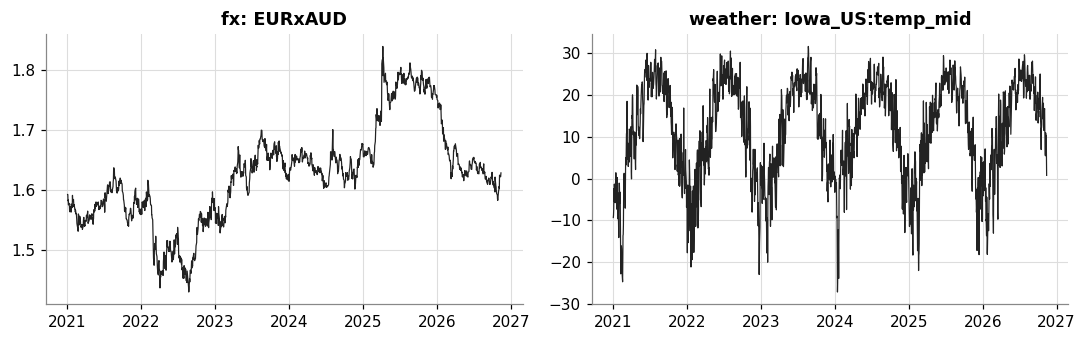

In [15]:
series = data.load_all(cfg)
info = pd.DataFrame([dict(series=s.name, domain=s.domain, n_obs=len(s), first=str(s.dates[0]), last=str(s.dates[-1])) for s in series])
display(info.groupby("domain").agg(n_series=("series", "count"), median_obs=("n_obs", "median"), first=("first", "min"), last=("last", "max")))
doms = [d for d in ("fx", "fred", "weather") if any(x.domain == d for x in series)]
fig, axs = plt.subplots(1, len(doms), figsize=(5 * len(doms), 3.2), squeeze=False)
for ax, dom in zip(axs[0], doms):
    s = next(x for x in series if x.domain == dom)
    ax.plot(s.dates, s.values, lw=0.8, color="#222"); ax.set_title(f"{dom}: {s.name}")
plt.tight_layout(); plt.show()

## 5. Forecast origins
Every Monday-spaced week from `first_origin` is an origin. At each origin a model sees the history so far and forecasts the next 14 steps; the realised values and their **dates** are stored, because the date tells us when an outcome becomes known.

In [16]:
panel = build_panel(series, cfg)
print(f"{len(series)} series x {len(panel.odates)} origins ({panel.odates[0]} -> {panel.odates[-1]}); usable pairs: {int(panel.valid.sum()):,}")

101 series x 181 origins (2023-06-01 -> 2026-11-12); usable pairs: 18,050


## 6. Run every forecaster (cached)
Classical models take seconds to minutes. Foundation models are the slow part (fast on a GPU, much slower on CPU). Results are saved to `cache/`, so a re-run, or a crash and restart, loses nothing.

In [17]:
Qs = run_all(series, panel, cfg, forecasters_ok)
print("forecasts available for:", list(Qs))

    snaive: 400/18050 forecasts (2s)
    snaive: 800/18050 forecasts (2s)
    snaive: 1200/18050 forecasts (2s)
    snaive: 1600/18050 forecasts (2s)
    snaive: 2000/18050 forecasts (2s)
    snaive: 2400/18050 forecasts (2s)
    snaive: 2800/18050 forecasts (2s)
    snaive: 3200/18050 forecasts (2s)
    snaive: 3600/18050 forecasts (2s)
    snaive: 4000/18050 forecasts (2s)
    snaive: 4400/18050 forecasts (2s)
    snaive: 4800/18050 forecasts (2s)
    snaive: 5200/18050 forecasts (2s)
    snaive: 5600/18050 forecasts (2s)
    snaive: 6000/18050 forecasts (2s)
    snaive: 6400/18050 forecasts (2s)
    snaive: 6800/18050 forecasts (3s)
    snaive: 7200/18050 forecasts (3s)
    snaive: 7600/18050 forecasts (3s)
    snaive: 8000/18050 forecasts (3s)
    snaive: 8400/18050 forecasts (3s)
    snaive: 8800/18050 forecasts (3s)
    snaive: 9200/18050 forecasts (3s)
    snaive: 9600/18050 forecasts (3s)
    snaive: 10000/18050 forecasts (3s)
    snaive: 10400/18050 forecasts (3s)
    snaive: 

## 7. Statistics
This builds the four interval types (native, split conformal, CQR, adaptive CQR) for every model with **no look-ahead**, then computes coverage, width, Winkler score and point error per window, with cluster-bootstrap intervals over series.
The conformal step is the slowest analysis step.

In [18]:
study = Study(panel, Qs, cfg)
tabs = dict(summary=study.summary_table(), skill=study.skill_shift_table(), covshift=study.coverage_shift_table(),
            horizon=study.horizon_table(), monthly=study.monthly_coverage(), qcal=study.quantile_calibration(), cost=study.width_cost_table(),
            sens_cal=study.sensitivity_cal(), sens_win=study.sensitivity_window())
print("windows used (targets):")
for k, v in study.windows.items():
    print(f"  {k:20s} pre {v['pre'][0]} -> {v['pre'][1]}   post {v['post'][0]} -> {v['post'][1]}")

  building conformal intervals (this is the slowest analysis step) ...
  common-support elements: 68,001
windows used (targets):
  global               pre 2023-11-27 -> 2024-11-26   post 2025-10-20 -> 2026-11-13
  chronos_bolt_small   pre 2023-11-27 -> 2024-11-26   post 2024-11-26 -> 2025-11-26
  chronos_bolt_base    pre 2023-11-27 -> 2024-11-26   post 2024-11-26 -> 2025-11-26
  chronos_2            pre 2024-10-20 -> 2025-10-20   post 2025-10-20 -> 2026-10-20


In [19]:
s = tabs["summary"]
key = s[(s.wset == "global") & (s.period == "post") & (s.domain == "all")][["model", "method", "coverage", "cov_lo", "cov_hi", "width", "wink", "mase", "n_series"]]
display(key.round(3).sort_values(["model", "method"]).reset_index(drop=True))

,model,method,coverage,cov_lo,cov_hi,width,wink,mase,n_series
0,chronos_2,aci,0.790,0.785,0.796,4.435,6.959,1.357,101
1,chronos_2,cqr,0.798,0.792,0.805,4.414,6.854,1.357,101
2,chronos_2,native,0.746,0.725,0.765,4.151,6.645,1.357,101
3,chronos_2,scp,0.799,0.791,0.806,4.502,7.768,1.357,101
4,chronos_bolt_base,aci,0.794,0.789,0.799,4.562,7.222,1.400,101
5,chronos_bolt_base,cqr,0.803,0.797,0.809,4.536,7.099,1.400,101
6,chronos_bolt_base,native,0.776,0.756,0.795,4.419,6.893,1.400,101
7,chronos_bolt_base,scp,0.797,0.790,0.805,4.659,7.996,1.400,101
8,chronos_bolt_small,aci,0.792,0.787,0.798,4.518,7.196,1.398,101
9,chronos_bolt_small,cqr,0.797,0.790,0.803,4.461,7.065,1.398,101


## 8. Figures
1. data and release dates; 2. coverage before and after release (all methods, per domain); 3. coverage over time; 4. width versus coverage;
5. does the point-forecast advantage shrink after release; 6. change in coverage relative to the classical control; 7. coverage by horizon; 8. quantile reliability.

f1_data.png


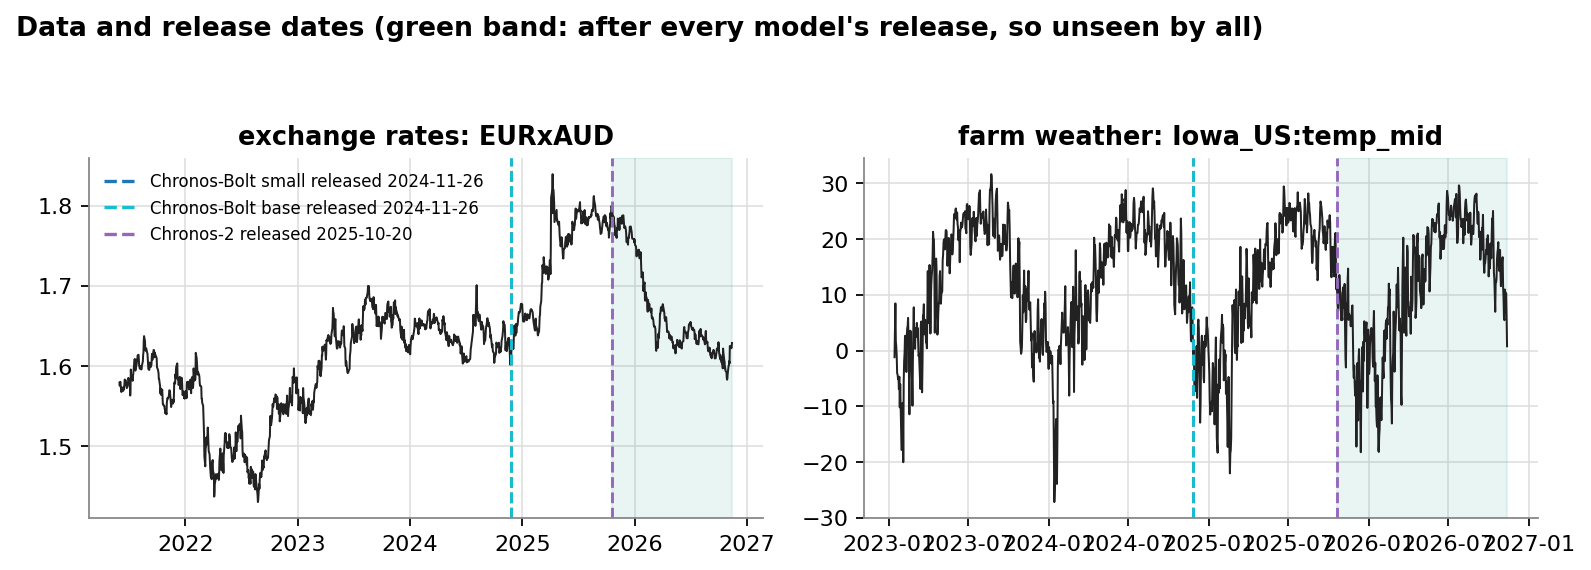

f2_coverage.png


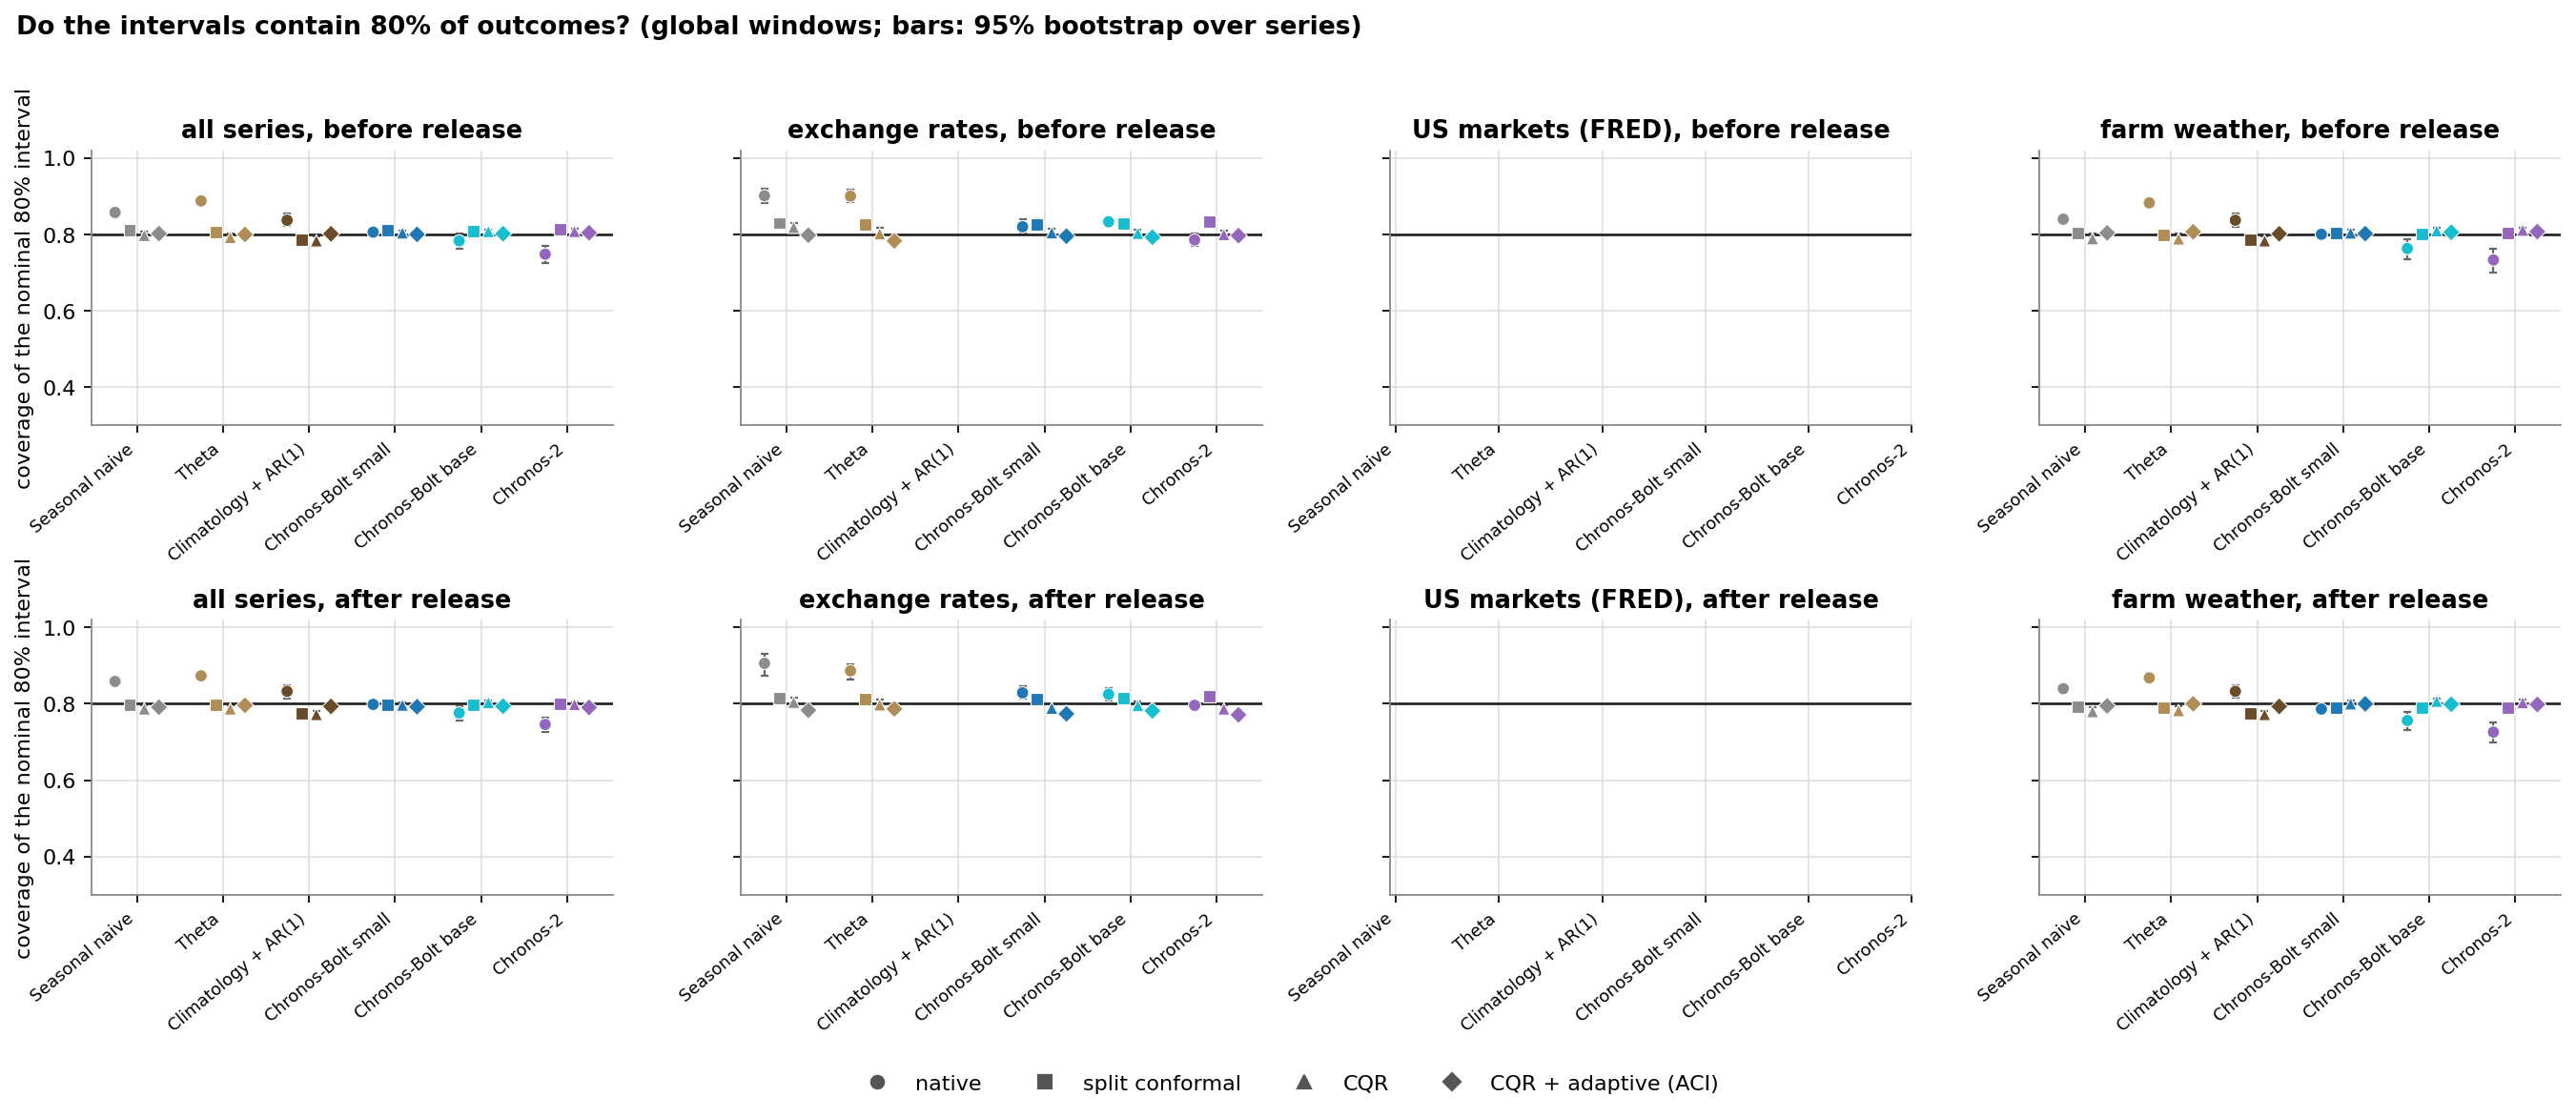

f3_coverage_over_time.png


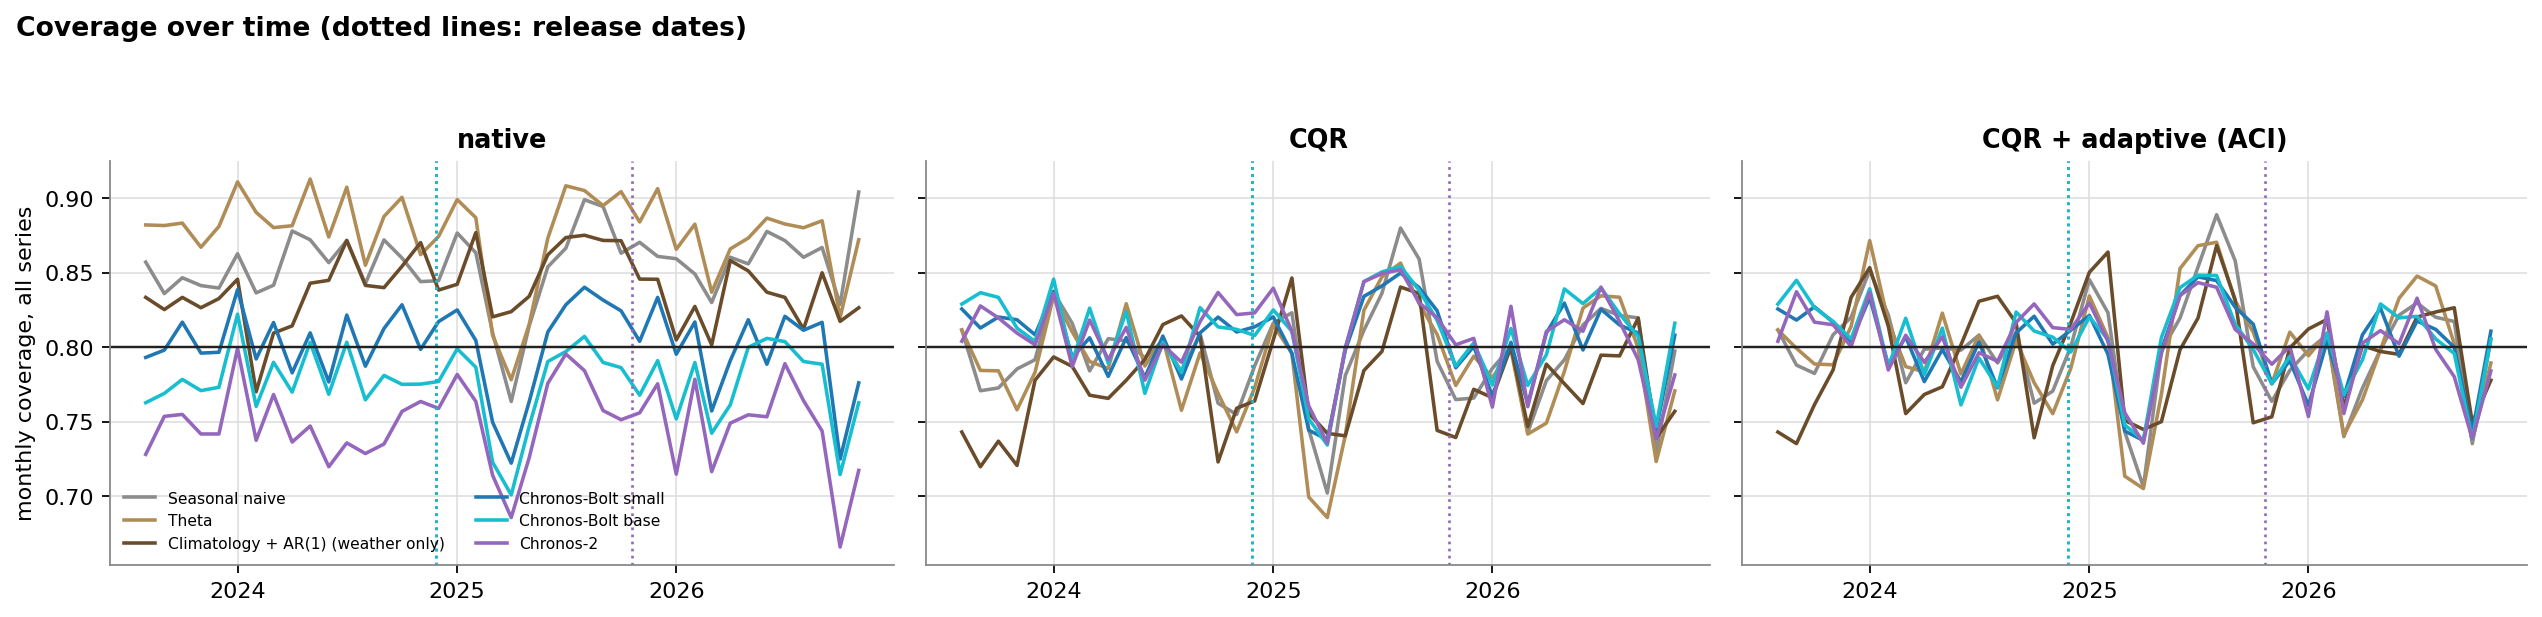

f4_width_vs_coverage.png


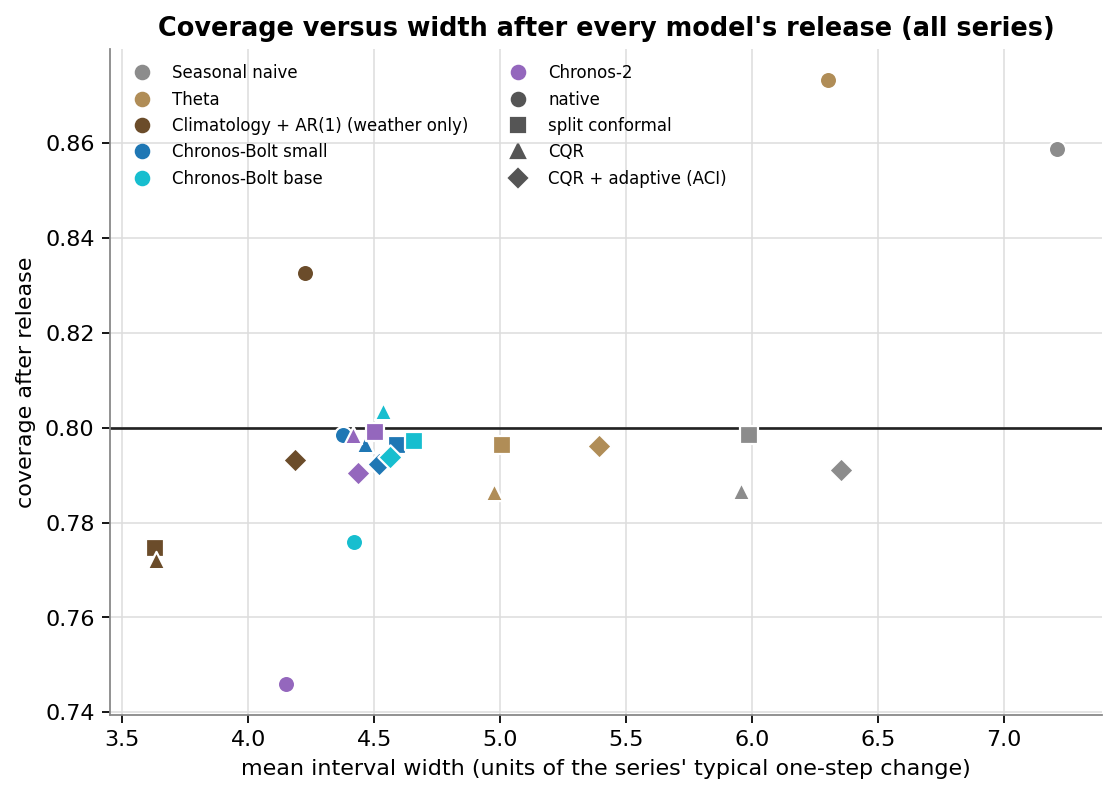

f5_skill_shift.png


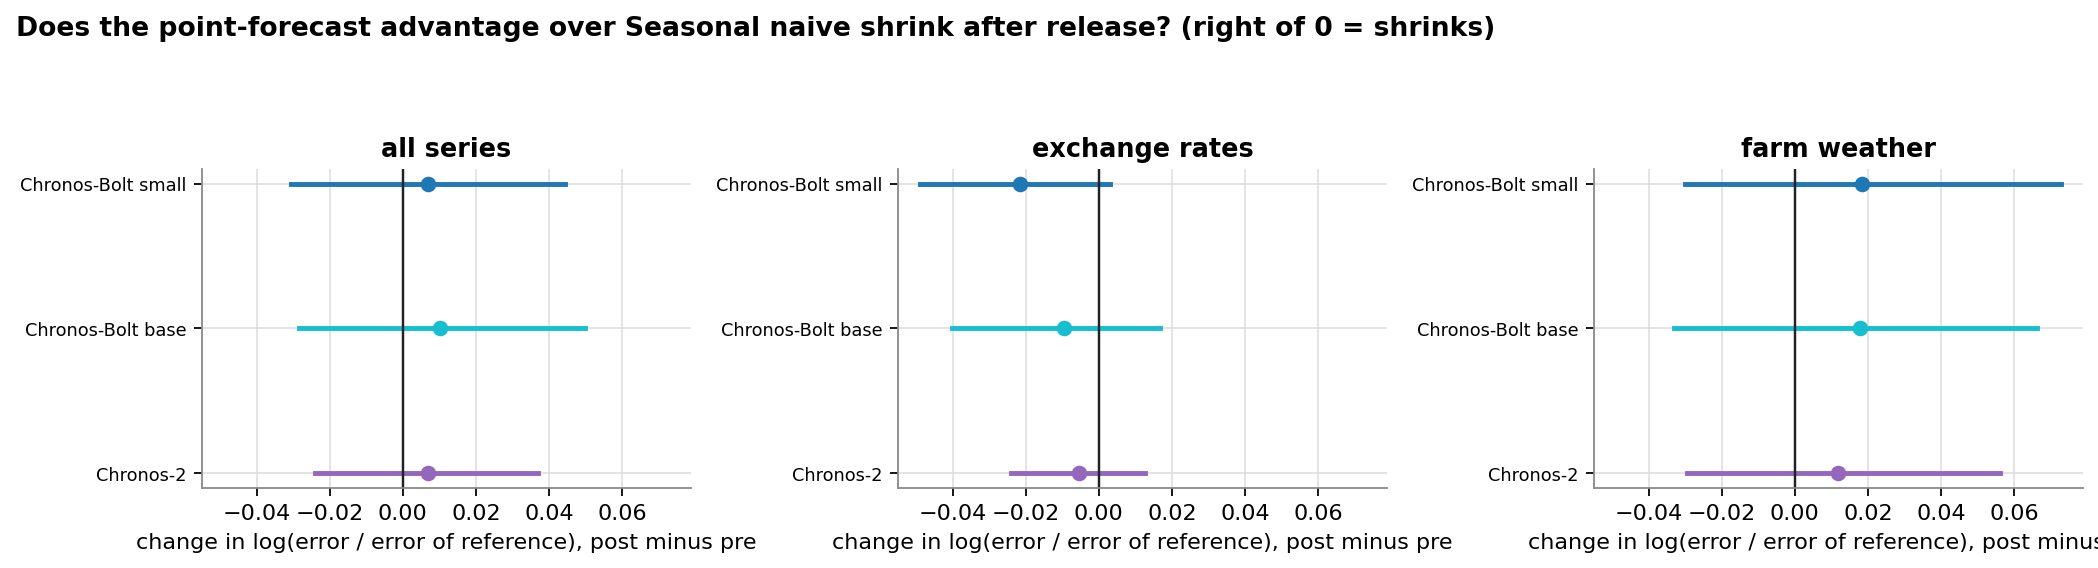

f6_coverage_shift.png


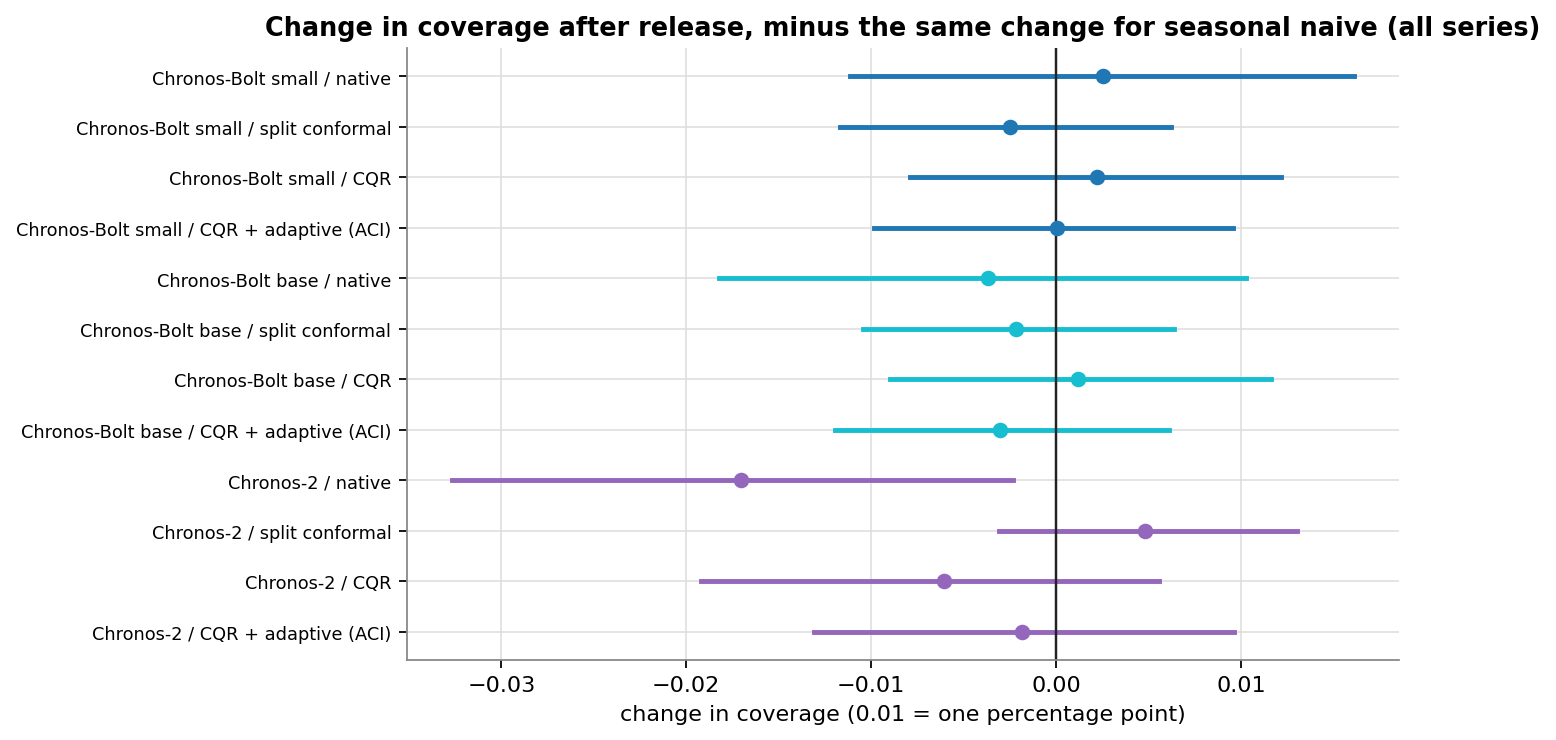

f7_horizon.png


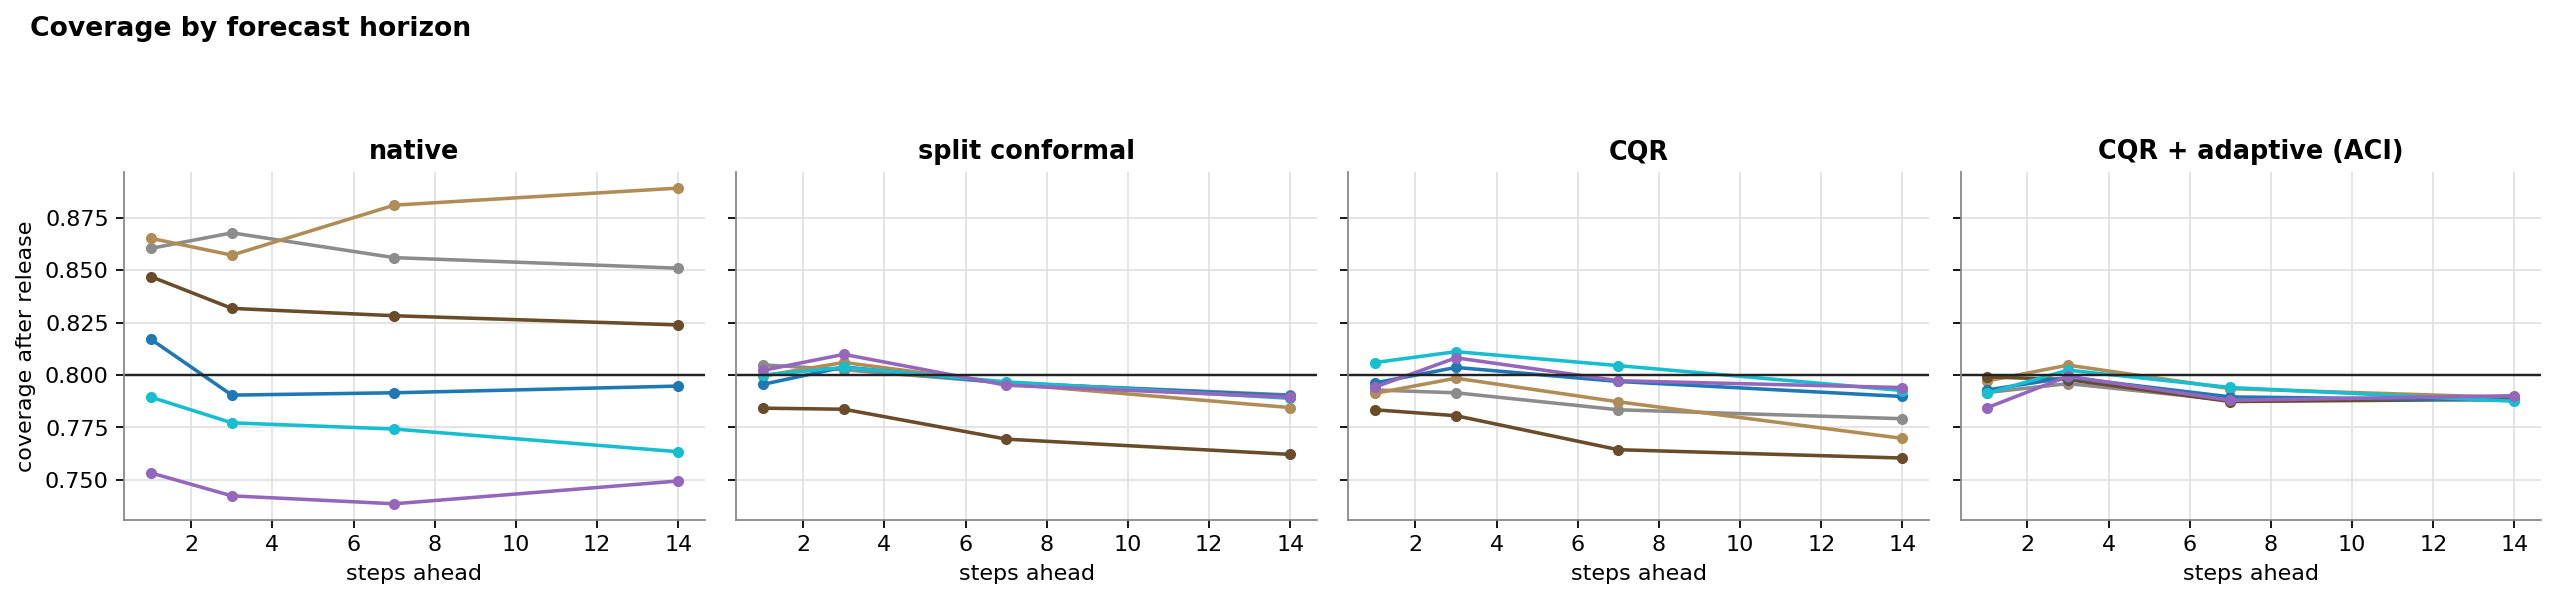

f8_quantile_calibration.png


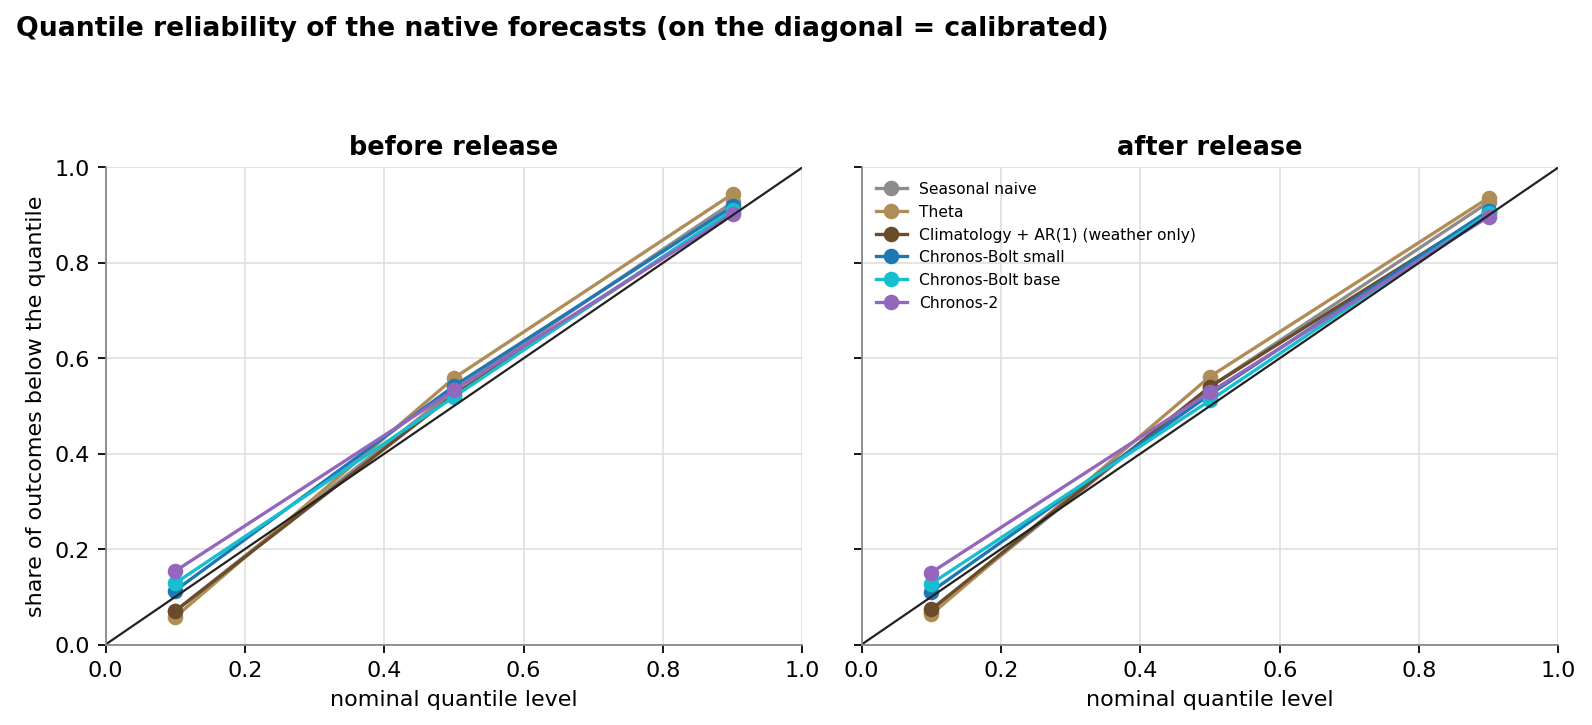

f9_sensitivity.png


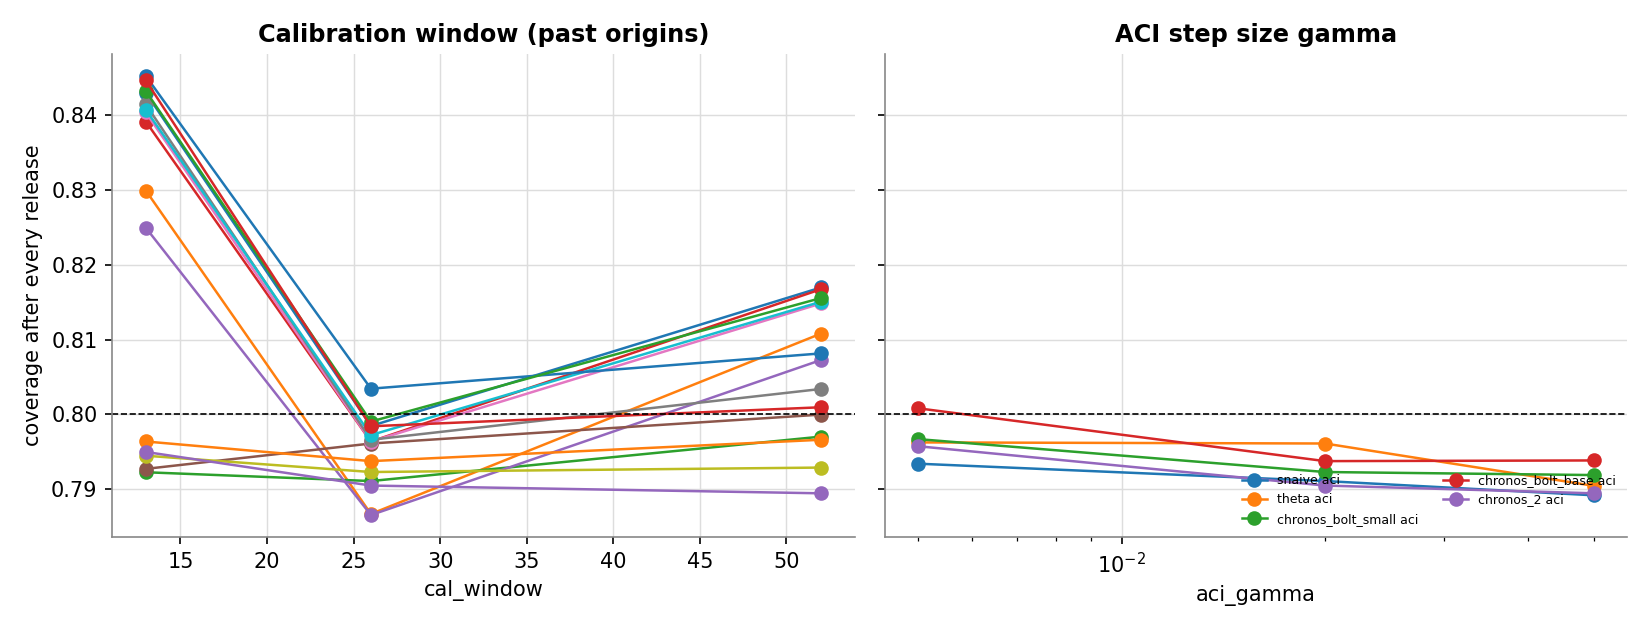

In [20]:
figures.make_all(study, tabs, cfg, series, panel)
for f in sorted(os.listdir(cfg.out_dir)):
    if f.endswith(".png"):
        print(f); display(Image(os.path.join(cfg.out_dir, f)))

## 9. Conclusion (written by code from the tables above)
Every sentence comes from a table. A result is called reliable only if its 95% bootstrap interval excludes the null value; otherwise the text says the data cannot tell the difference.
The limits are listed with the results so they cannot be separated from them.

In [21]:
text = report.conclusion_text(study, tabs, cfg)
print(text)
open(os.path.join(cfg.out_dir, "conclusion.txt"), "w", encoding="utf-8").write(text)

CONCLUSION (computed from this run: 101 series = 29 exchange-rate, 0 US-market, 72 farm-weather; 181 weekly forecast origins; horizons [1, 3, 7, 14] steps; nominal interval 80%)
Windows: before every release = targets from 2023-11-27 to 2024-11-26; after every release = targets from 2025-10-20 to 2026-11-13. Release dates are upper bounds on the end of each model's training data.

RQ1. Do the native 80% intervals of foundation models hold after their release?
  Chronos-Bolt small: after release 0.80 [0.79, 0.81]: consistent with 0.80; before release 0.81. Change after minus before -0.003 [-0.014, +0.007]; relative to seasonal naive +0.003 [-0.011, +0.016] -> no reliable difference
  Chronos-Bolt base: after release 0.77 [0.75, 0.79]: below the nominal 0.80 (undercovers); before release 0.78. Change after minus before -0.009 [-0.021, +0.004]; relative to seasonal naive -0.004 [-0.018, +0.010] -> no reliable difference
  Chronos-2: after release 0.75 [0.73, 0.77]: below the nominal 0.80 

7222

## 10. Save the run for the report
Tables are in `outputs/table_*.csv`, figures in `outputs/*.png`, the conclusion in `outputs/conclusion.txt`. The cell below also records package versions and the exact settings, so the run can be reproduced.

In [22]:
import json, platform, importlib
vers = {}
for m in ("numpy", "pandas", "scipy", "matplotlib", "torch", "chronos", "transformers"):
    try:
        vers[m] = importlib.import_module(m).__version__
    except Exception:
        vers[m] = "not installed"
from dataclasses import asdict
run_info = dict(python=platform.python_version(), packages=vers, settings=asdict(cfg), models_run=list(Qs),
                windows={k: {p: [str(a), str(b)] for p, (a, b) in v.items()} for k, v in study.windows.items()})
json.dump(run_info, open(os.path.join(cfg.out_dir, "run_info.json"), "w"), indent=2, default=str)
run_info["packages"]

{'numpy': '2.4.6',
 'pandas': '2.2.3',
 'scipy': '1.16.3',
 'matplotlib': '3.10.0',
 'torch': '2.14.1+cu130',
 'chronos': '2.3.2',
 'transformers': '5.22.1'}